---
title: "Zahradnik regime transition in a bubble column"
description: "The homogeneous and the heterogeneous branch of Zahradnik et al. are each fitted by their own model. Neither model, nor the two together, fixes the printed transition: it is where the data leave the fitted homogeneous line, and the printed numbers are consistent with that reading."
categories: [sec:F, struct:S1, tier:T1, data:tier4, phase:gas-liquid]
date: 2026-11-27
---

# Zahradnik regime transition in a bubble column

**Catalog ID:** `F1.9` · **Structures:** `S1` (algebraic closures and their roots) · **Tier:** T1

A bubble column run with a fine distributor starts in the homogeneous regime: small
bubbles of one size, holdup rising almost linearly with gas velocity. At some gas
velocity the bed turns churn-turbulent, large bubbles appear, and the holdup falls
back before it rises again. Where that happens decides which holdup and mixing
correlations apply.

Zahradnik et al. (1997) fit each regime with its own model, a slip-velocity model
for the homogeneous branch and the Zuber-Findlay drift-flux model for the
heterogeneous one, and print the transition for air-water in a 0.15 m column as a
pair of numbers. This page asks whether either fitted model, or the two together,
fixes that pair, or whether it is a property of the data alone.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F1.9-zahradnik-regime-transition"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip. The page is
# algebra: there is no balance to discretise, and the only pymrm call is
# pymrm.checks.find_roots, which brackets every root, maximum and crossing the page reports.
import re
from dataclasses import dataclass, field, replace
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import quad
from scipy.optimize import minimize_scalar
from pymrm.checks import find_roots
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``. Formats are Python formats, or
    ``pctN`` / ``+pctN`` for a fraction shown as a percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

The paper (Zahradnik, Fialova, Ruzicka, Drahos, Kastanek and Thomas, *Chem. Eng.
Sci.* 52, 3811-3826, 1997) collects holdup, mixing and $k_La$ data across the two
regimes for many distributors, geometries and liquids. Its section "Bubble flow
models" treats the two regimes separately. The homogeneous branch is fitted with the
slip-velocity concept and the six hindrance functions of its Table 2; the transition
is placed where the data leave that line, and the paper names a pair for air-water:
"(u_OG)crit = 0.04 m s-1 and (eps_G)crit = 0.210" (p. 3821). It links the departure to
"the appearance of the first turbulent disturbances in the bed" (p. 3821), not to
either model. The heterogeneous branch is fitted with Zuber-Findlay (eq. 10), and the
fully developed heterogeneous regime is placed at "u_OG ≥ 0.125 m s-1" (p. 3815).

The question here: does anything in the two fitted models fix the printed pair? Two
candidates can be tested from printed constants alone: (a) the homogeneous branch's
own limit, the maximum of its drift flux, which is the only parameter-free point of
that model, and (b) a meeting of the two branches. The positive half of the answer
is a check that the printed numbers are mutually consistent: the pair against the
fitted line and the plotted markers, the rejoin of the heterogeneous line, and the
airlift riser's slope breaks.

Not covered: Table 1 and the salt solutions, residence-time distributions and Péclet
numbers (Fig. 2), $k_La$ (Fig. 3), the effects of distributor, geometry, solutes and
viscosity (Figs. 4 to 10): the paper prints no model for them. No stability theory is
evaluated (the dynamic-wave criteria need coefficients the paper does not print).
Wilkinson's transition correlation is on F1.3, the large-bubble holdup of the
churn-turbulent regime on F1.4.

## The published model

Velocities are superficial, $u_G$ (the paper's $u_{OG}$) and $u_L$; $j = u_G + u_L$.
The paper's $u_{b\infty}$ names two different things (misprint M9 below): the
terminal velocity in eqs. 4 and 5 (written $u_{b\infty}$ here) and the drift-flux
intercept of eqs. 7, 8 and 10 (written $u_d$ here).

| id | equation | source |
|---|---|---|
| E1 | $u_s = u_G/\varepsilon \mp u_L/(1-\varepsilon)$, "+ refers to countercurent flow and – to cocurrent flow" | eq. 3, p. 3820 |
| E2 | $u_s = u_{b\infty}\,\phi(\varepsilon)$ | eq. 4, p. 3821 |
| E3 | $\varepsilon = u_G/(u_{b\infty}\phi(\varepsilon))$ ($u_L = 0$), written as the homogeneous drift flux $u_G = j_h(\varepsilon) = u_{b\infty}\varepsilon\phi(\varepsilon)$ | eq. 5, p. 3821 |
| E4 | Table 2: Turner $\phi = 1$; Davidson-Harrison $1/(1-\varepsilon)$; Griffith-Wallis $1-\varepsilon$; Richardson-Zaki $(1-\varepsilon)^{1.39}$; Marrucci $(1-\varepsilon)/(1-\varepsilon^{5/3})$; Joshi-Lali $1/(7.5\varepsilon^2+1)^{1/2}$ | Table 2, p. 3821 |
| E5 | $\phi = A_c/(1-\varepsilon)$, "modified equation of Davidson and Harrison", $A_c = 0.79$ (airlift riser) | eq. 6, pp. 3821-3822 |
| E6 | page identity: E1 (cocurrent) with E2 and E5 gives $u_G/\varepsilon = j + A_c u_{b\infty}$, Zuber-Findlay with $C_0 = 1$ | page |
| E7 | $\varepsilon = u_G/(C_0 j + u_d)$, i.e. $u_G/\varepsilon = C_0 j + u_d$ | eqs. 7, 8, p. 3822 |
| E8 | $(\varepsilon - \varepsilon_w)/(\varepsilon_c - \varepsilon_w) = 1 - (r/R_r)^7$, "C0 = 1.07 provided that eps_wall/eps_centre = 0.5" | eq. 9, p. 3823 |
| E9 | eq. 10 $\varepsilon = u_G/(2.02u_G + 0.257)$; eq. 11 $u_G/(2u_G + u_{b\infty})$; eq. 12 $u_G/(2u_G + 0.3)$, "virtually identical" | eqs. 10-12, p. 3823 |
| E10 | $u_{drift} = 1.53(\sigma g\Delta\rho/\rho_L^2)^{1/4}$, printed value 0.250 m/s | eq. 13, p. 3823 |
| E11 | $u_{b\infty} = (\mu_L/(\rho_L d_b))Mo^{-0.149}(J - 0.857)$, $J = 0.94H_d^{0.757}$ ($2 < H_d < 59.3$), $3.42H_d^{0.441}$ ($H_d > 59.3$), $H_d = \tfrac43 Eo\,Mo^{-0.149}(\mu_L/\mu_w)^{-0.14}$, $d_b = 1.8(\sigma/(\Delta\rho g))^{0.5}$, printed value 0.267 m/s | eq. 14, p. 3823 |
| E12 | page: the kinematic limit of the homogeneous branch, $dj_h/d\varepsilon = 0$; $dj_h/d\varepsilon$ is the kinematic wave speed | page |
| E13 | page: the branches meet where $u_{b\infty}\phi(\varepsilon)(1 - C_0\varepsilon) = u_d$; since $\phi(\varepsilon)(1 - C_0\varepsilon) \le 1$ for all six forms (Davidson-Harrison: $(1 - C_0\varepsilon)/(1 - \varepsilon) < 1$ as $C_0 > 1$) and $u_{b\infty} < u_d$ the left side never reaches $u_d$ | page |
| E14 | page: each Fig. 11(a) marker gives $u_G = y\,\varepsilon\,u_{b\infty}$, $y = u_s/u_{b\infty}$ (semibatch) | page |

| symbol | code |
|---|---|
| $u_{b\infty}$ (eqs. 4, 5) | `K["u_b_inf_homogeneous"]` |
| $C_0$, $u_d$ of eq. 10 | `K["C0_column_plateB"]`, `K["u_drift_column_plateB"]` |
| $\phi$ of Table 2 | `phi(form, e, K, C)` |
| $j_h(\varepsilon)$, $dj_h/d\varepsilon$ | `jh`, `djh` |

Misprints and ambiguities, recorded and not corrected unless stated:
**M1, M2** the $Mo$ and $Eo$ of the eq. 14 block are not dimensionless ($Mo$ printed
$g\mu_L\Delta\rho/(\rho_L^2\sigma)$, $Eo$ printed with $d_b$ for $d_b^2$); the page uses
Clift's groups $Mo = g\mu_L^4\Delta\rho/(\rho_L^2\sigma^3)$, $Eo = g\Delta\rho d_b^2/\sigma$
and shows what the printed groups give. **M6** "By re-arranging eq. (8)" precedes
eq. 8: it re-arranges eq. 7. **M8** in the scan the Joshi-Lali exponent of Table 2 reads "1.2";
the scan breaks every solidus of that table into dots (the Marrucci exponent reads "5:3"),
and the Fig. 11(b) legend prints "1/2", which the page uses. This is the scan, not a misprint. **M9** the two meanings of
$u_{b\infty}$ above. **M10** the riser $u_{b\infty}$ behind eq. 6 is not restated; the
page takes 0.235 m/s (same section, same symbol) and shows the verdict's sensitivity
to it. **M12** eq. 9 alone does not give $C_0$: the velocity profile is not printed.
p. 3814 prints "0.04 m s-11" (a superscript slip).

## Parameters and assumptions

Every constant is a printed string in `data/zahradnik-1997-printed-numbers.csv`,
read as text and compared in half-units of its last printed digit. All of them sit
in one dictionary `K` that every function takes, so a break-table row can mistype one
constant and rerun the page.

- The paper states no temperature and no fluid property. Eqs. 13 and 14 need water
  properties; the page uses water at 20 C (external inputs, below) and shows eq. 13
  at 15 C and 25 C beside it. Nothing here is a statement about the experiments'
  temperature.
- $\mu_w$ of eq. 14 is not printed ("w water"); the page takes Clift's reference
  value 0.0009 Pa s.
- Fig. 11(a) is drawn with $u_{b\infty}$ = 0.235 m/s (p. 3821); the markers are
  converted with the same value (E14).
- The airlift riser rows (R5) use the printed slope breaks; the riser $u_L$ is not
  printed except through them.

In [3]:
PN = load_data("zahradnik-1997-printed-numbers.csv", page=PAGE, dtype=str)
PRINTED = dict(zip(PN.name, PN.value))


def _num(s):
    try:
        return float(Fraction(s))
    except ValueError:
        return None


K = {k: _num(v) for k, v in PRINTED.items() if _num(v) is not None}
display(PN[["name", "value", "unit", "journal_page", "where"]].set_index("name"))
# External inputs (not from the paper), used by eqs. 13 and 14 only.
WATER = {   # T in C: rho_L kg/m3, mu_L Pa s, sigma N/m, rho_G (air) kg/m3
    20: dict(rho_L=998.21, mu_L=1.0016e-3, sigma=0.07275, rho_G=1.204),
    15: dict(rho_L=999.10, mu_L=1.1375e-3, sigma=0.07349, rho_G=1.225),
    25: dict(rho_L=997.05, mu_L=0.8900e-3, sigma=0.07197, rho_G=1.184),
}
G = 9.80665          # m/s2
MU_W = 0.0009        # Pa s, Clift et al. (1978) reference viscosity of eq. 14
FORMS = ("turner", "davidson_harrison", "griffith_wallis", "richardson_zaki", "marrucci", "joshi_lali")
NAME = dict(turner="Turner", davidson_harrison="Davidson-Harrison", griffith_wallis="Griffith-Wallis",
            richardson_zaki="Richardson-Zaki", marrucci="Marrucci", joshi_lali="Joshi-Lali")
SHORT = dict(turner="turner", davidson_harrison="dh", griffith_wallis="gw", richardson_zaki="rz",
             marrucci="marrucci", joshi_lali="jl")


def half_unit(name):
    """Half a unit of the last printed digit of constant ``name``."""
    s = PRINTED[name].strip().lstrip("-")
    return 0.5 * 10.0 ** -(len(s.split(".")[1]) if "." in s else 0)


def halfunits(x, name, K):
    """Distance of ``x`` from printed constant ``name``, in half-units of its last digit."""
    return abs(x - K[name]) / half_unit(name)

,value,unit,journal_page,where
name,,,,
u_b_inf_homogeneous,0.235,m/s,3821,text Bubble flow models 1
u_G_crit,0.04,m/s,3821,text Bubble flow models 1
eps_G_crit,0.210,-,3821,text Bubble flow models 1
u_G_onset_fig3a,0.04,m/s,3814,text Fig. 3(a) discussion
u_G_heterogeneous_full,0.125,m/s,3815,text Fig. 3(a) discussion
rz_exponent_air_water,1.39,-,3821,Table 2
marrucci_exponent,5/3,-,3821,Table 2
joshi_lali_coefficient,7.5,-,3821,Table 2
joshi_lali_exponent_fig11b,1/2,-,3821,Fig. 11(b) legend


## The data

- **Printed numbers** (pp. 3814, 3815, 3821 to 3823): constants, limits and results
  with a short quote each.
- **Fig. 11(a)** (p. 3821): $u_s/u_{b\infty}$ against $\varepsilon$ for air-water,
  plate A, with the drawn Table 2 lines 1 to 5. The markers and the readings of the
  drawn lines (counts printed below) are digitised from the native 300 ppi scan by `data/digitise.py`; the
  sidecar gives the rotation correction and the calibration. Reading error per
  marker: $\sigma_\varepsilon$ = 0.001, $\sigma_y$ = 0.007 (sidecar).
- **Fig. 3(a)** (p. 3815): holdup against $u_G$ for plates A and B in the same column;
  it tests the $u_{b\infty}$ normalisation of Fig. 11(a) (Validation V2).
- **Fig. 12(b)** (p. 3822): the drift-flux plot behind eq. 10 (plate B); it checks
  eq. 10 and gives the yardstick of the scatter about it (Validation V3).
- Fig. 11(b) and 12(a) (the riser) are not digitised: the riser $u_L$ of each marker
  is not printed, and the slope breaks are printed in the text.

Every figure value is a tier-4 reading; each number built on one is printed with
the reading error beside it.

In [4]:
F11 = load_data("zahradnik-1997-fig11a.csv", page=PAGE)
F3 = load_data("zahradnik-1997-fig3a.csv", page=PAGE)
F12 = load_data("zahradnik-1997-fig12b.csv", page=PAGE)
for name in ("zahradnik-1997-printed-numbers", "zahradnik-1997-fig11a", "zahradnik-1997-fig3a",
             "zahradnik-1997-fig12b"):
    print(cite_data(load_meta(name + ".csv", page=PAGE)))
SIG_EPS, SIG_Y = 0.001, 0.007   # Fig. 11(a) reading error per marker (sidecar)
SIG_LINE = 0.005                # Fig. 11(a) reading error of a drawn-line point in y: "about 1 px (0.004 in y)" (sidecar), rounded up
SIG_EPS3, SIG_U3 = 0.001, 0.0005  # Fig. 3(a) reading error per marker (sidecar), m/s for u
REL_U11 = 0.006                 # relative error of u_G = y eps u_binf at a Fig. 11(a) marker (sidecar)


@dataclass(frozen=True)
class Data:
    """The page's inputs besides the printed constants."""
    f11: pd.DataFrame
    f3: pd.DataFrame
    f12: pd.DataFrame
    ub_fig: float = 0.235           # m/s, the u_binf Fig. 11(a) is normalised with (p. 3821)
    forms: dict = field(default_factory=lambda: {f: f for f in FORMS})   # Table 2 row -> formula used
    ref: str = "griffith_wallis"    # the form the departure (R4b) is judged against
    het: tuple = ("C0_column_plateB", "u_drift_column_plateB")   # eq. 10 constants used in R4d
    water: dict = field(default_factory=lambda: dict(WATER))
    printed_groups: bool = False    # eq. 14 with the block's groups as printed (M1, M2)
    rho_pow: float = 2.0            # power of rho_L in the denominator of eq. 13
    mu_w: float = MU_W              # Pa s, reference viscosity of eq. 14
    sig_eps: float = SIG_EPS
    sig_y: float = SIG_Y


C = Data(F11, F3, F12)
print(f"Fig. 11(a): {int((F11.kind == 'marker').sum())} markers, {int((F11.kind == 'line').sum())} line readings; "
      f"Fig. 3(a): {len(F3)} markers; Fig. 12(b): {len(F12)} markers")

Zahradnik, J.; Fialova, M.; Ruzicka, M.; Drahos, J.; Kastanek, F.; Thomas, N. H. (1997) — Chemical Engineering Science 52, 3811-3826 — doi:10.1016/S0009-2509(97)00226-1 — transcribed
Zahradnik, J.; Fialova, M.; Ruzicka, M.; Drahos, J.; Kastanek, F.; Thomas, N. H. (1997) — Chemical Engineering Science 52, 3811-3826 — doi:10.1016/S0009-2509(97)00226-1 — digitised from Fig. 11(a), journal page 3821 (PDF page 11)
Zahradnik, J.; Fialova, M.; Ruzicka, M.; Drahos, J.; Kastanek, F.; Thomas, N. H. (1997) — Chemical Engineering Science 52, 3811-3826 — doi:10.1016/S0009-2509(97)00226-1 — digitised from Fig. 3(a), journal page 3815 (PDF page 5)
Zahradnik, J.; Fialova, M.; Ruzicka, M.; Drahos, J.; Kastanek, F.; Thomas, N. H. (1997) — Chemical Engineering Science 52, 3811-3826 — doi:10.1016/S0009-2509(97)00226-1 — digitised from Fig. 12(b), journal page 3822 (PDF page 12)
Fig. 11(a): 21 markers, 38 line readings; Fig. 3(a): 22 markers; Fig. 12(b): 8 markers


## PyMRM implementation

There is nothing to discretise. Every holdup on the homogeneous branch is a root of
E3 found by `pymrm.checks.find_roots` over the whole physical range
$(10^{-9}, 1-10^{-9})$, scanned on a log grid below 0.01 and a linear grid above, so
a root near 0.01 is seen as well as one near 1; the count of roots is part of the
result (two on the Griffith-Wallis and Richardson-Zaki branches, one elsewhere). A
flux maximum is a root of the numerator of $dj_h/d\varepsilon$ (positive factors
multiplied out), a crossing of the branches a root of E13, the riser flip velocity
and the eq. 9 exponent roots in one variable. The second routes are closed forms,
the paper's fixed-point form of eq. 5, a bounded maximisation refined from a scan of
the window and an independent quadrature (Validation V1).

In [5]:
def phi(form, e, K, C):
    """Table 2 hindrance function ``form`` (as mapped by ``C.forms``) at holdup ``e``."""
    f = C.forms[form]
    if f == "turner":
        return 1.0 + 0.0 * e
    if f == "davidson_harrison":
        return 1.0 / (1.0 - e)
    if f == "griffith_wallis":
        return 1.0 - e
    if f == "richardson_zaki":
        return (1.0 - e) ** K["rz_exponent_air_water"]
    if f == "marrucci":
        return (1.0 - e) / (1.0 - e ** K["marrucci_exponent"])
    if f == "joshi_lali":
        return 1.0 / (K["joshi_lali_coefficient"] * e ** 2 + 1.0) ** K["joshi_lali_exponent_fig11b"]
    raise ValueError(f)


def jh(form, e, K, C, ub=None):
    """Homogeneous drift flux u_G = u_binf eps phi(eps) (E3)."""
    return (K["u_b_inf_homogeneous"] if ub is None else ub) * e * phi(form, e, K, C)


def djh_numerator(form, e, K, C):
    """dj_h/deps with its positive factors multiplied out: its roots are the flux maxima."""
    f = C.forms[form]
    if f in ("turner", "davidson_harrison"):
        return 1.0 + 0.0 * e
    if f == "griffith_wallis":
        return 1.0 - 2.0 * e
    if f == "richardson_zaki":
        return 1.0 - (K["rz_exponent_air_water"] + 1.0) * e
    if f == "marrucci":
        p = K["marrucci_exponent"]
        return (1.0 - 2.0 * e) * (1.0 - e ** p) + p * e ** p * (1.0 - e)
    if f == "joshi_lali":
        a, q = K["joshi_lali_coefficient"], K["joshi_lali_exponent_fig11b"]
        return 1.0 + a * e ** 2 * (1.0 - 2.0 * q)
    raise ValueError(f)


def djh(form, e, K, C):
    """The kinematic wave speed dj_h/deps, analytic (E12)."""
    ub, f = K["u_b_inf_homogeneous"], C.forms[form]
    if f == "turner":
        return ub
    if f == "davidson_harrison":
        return ub / (1.0 - e) ** 2
    if f == "griffith_wallis":
        return ub * (1.0 - 2.0 * e)
    if f == "richardson_zaki":
        n = K["rz_exponent_air_water"]
        return ub * (1.0 - e) ** (n - 1.0) * (1.0 - (n + 1.0) * e)
    if f == "marrucci":
        p = K["marrucci_exponent"]
        return ub * djh_numerator(form, e, K, C) / (1.0 - e ** p) ** 2
    a, q = K["joshi_lali_coefficient"], K["joshi_lali_exponent_fig11b"]
    return ub * djh_numerator(form, e, K, C) / (a * e ** 2 + 1.0) ** (q + 1.0)


def roots(f, lo, hi, split=1e-2):
    """Every root of ``f`` on [lo, hi] by find_roots: log scan below ``split``, linear above."""
    out = []
    if lo < split:
        out += find_roots(f, lo, min(split, hi), n_scan=200, log=True, xtol=1e-15)["roots"]
    if hi > split:
        out += find_roots(f, max(lo, split), hi, n_scan=600, xtol=1e-15)["roots"]
    out = sorted(out)
    return [r for i, r in enumerate(out) if i == 0 or r - out[i - 1] > 1e-12]


def eps_roots(form, u, K, C, ub=None):
    """All holdups on the homogeneous branch at gas velocity ``u`` (E3)."""
    return roots(lambda e: jh(form, e, K, C, ub) - u, 1e-9, 1.0 - 1e-9)


def eps_fixed_point(form, u, K, C):
    """The paper's form of eq. 5, eps = u/(u_binf phi(eps)), iterated from eps = u/u_binf."""
    ub, e = K["u_b_inf_homogeneous"], u / K["u_b_inf_homogeneous"]
    for _ in range(500):
        e_new = u / (ub * phi(form, e, K, C))
        if abs(e_new - e) < 1e-16:
            return e_new
        e = e_new
    return e


def eps10(u, K, keys=("C0_column_plateB", "u_drift_column_plateB")):
    """Zuber-Findlay with the constants named by ``keys`` (eq. 10 by default)."""
    return u / (K[keys[0]] * u + K[keys[1]])


def crossing_roots(form, K, C, ub):
    """Holdups where the homogeneous branch (u_binf = ub) meets eq. 10 (E13)."""
    C0, ud = K["C0_column_plateB"], K["u_drift_column_plateB"]
    return roots(lambda e: ub * phi(form, e, K, C) * (1.0 - C0 * e) - ud, 1e-9, min(1.0 / C0, 1.0) - 1e-12)


def eq13(w, K, C):
    """Zuber-Findlay drift velocity, eq. 13, for water properties ``w``."""
    drho = w["rho_L"] - w["rho_G"]
    return K["eq13_coefficient"] * (w["sigma"] * G * drho / w["rho_L"] ** C.rho_pow) ** K["eq13_exponent"]


def eq14_groups(w, d, K, C):
    """Mo, Eo and H_d of eq. 14 at bubble diameter ``d`` (Clift's groups, or as printed)."""
    drho, mu, rho, s = w["rho_L"] - w["rho_G"], w["mu_L"], w["rho_L"], w["sigma"]
    if C.printed_groups:
        Mo, Eo = G * mu * drho / (rho ** 2 * s), G * drho * d / s
    else:
        Mo, Eo = G * mu ** 4 * drho / (rho ** 2 * s ** 3), G * drho * d ** 2 / s
    Hd = K["eq14_Hd_coefficient"] * Eo * Mo ** K["eq14_Mo_exponent"] * (mu / C.mu_w) ** K["eq14_viscosity_exponent"]
    return Mo, Eo, Hd


def eq14_J(Hd, K, branch=None):
    low = K["eq14_J_low_coefficient"] * Hd ** K["eq14_J_low_exponent"]
    high = K["eq14_J_high_coefficient"] * Hd ** K["eq14_J_high_exponent"]
    if branch is None:
        branch = "low" if Hd < K["eq14_Hd_switch"] else "high"
    return low if branch == "low" else high


def eq14(w, d, K, C, branch=None):
    """Clift's terminal velocity, eq. 14, at bubble diameter ``d``."""
    Mo, Eo, Hd = eq14_groups(w, d, K, C)
    return w["mu_L"] / (w["rho_L"] * d) * Mo ** K["eq14_Mo_exponent"] * (eq14_J(Hd, K, branch) - K["eq14_J_offset"])


def d_at_Hd(w, Hd, K, C):
    """Bubble diameter at which H_d takes the value ``Hd`` (Clift's groups: H_d is d^2 times a constant)."""
    return np.sqrt(Hd / eq14_groups(w, 1.0, K, C)[2])


def mersmann(w, K):
    return K["mersmann_db_coefficient"] * np.sqrt(w["sigma"] / ((w["rho_L"] - w["rho_G"]) * G))


def eq9_C0(m, K, n=None):
    """C0 = <eps j>/(<eps><j>) for eq. 9's holdup profile and j/j_c = 1 - (r/R)^m (page, E8)."""
    a, n = K["eq9_wall_centre_ratio"], K["eq9_void_exponent"] if n is None else n
    jm = m / (m + 2.0)
    ej = a * jm + (1.0 - a) * (1.0 - 2.0 / (n + 2.0) - 2.0 / (m + 2.0) + 2.0 / (m + n + 2.0))
    return ej / ((a + (1.0 - a) * n / (n + 2.0)) * jm)


def eq9_C0_quad(m, K):
    """The same average by quadrature over the radius."""
    a, n = K["eq9_wall_centre_ratio"], K["eq9_void_exponent"]
    ep = lambda r: a + (1.0 - a) * (1.0 - r ** n)
    jj = lambda r: 1.0 - r ** m
    avg = lambda f: 2.0 * quad(lambda r: f(r) * r, 0.0, 1.0, epsabs=1e-13, epsrel=1e-12)[0]
    return avg(lambda r: ep(r) * jj(r)) / (avg(ep) * avg(jj))


def riser(K, i):
    """Riser at printed break ``i`` (1 or 2): u_L, eps by E6, u_s/u_binf, eps on the plate B line."""
    j, u = K[f"riser_break{i}_j"], K[f"riser_break{i}_u_G"]
    ud6 = K["A_c"] * K["u_b_inf_homogeneous"]
    e6 = u / (j + ud6)
    return dict(uL=j - u, e6=e6, slip=K["A_c"] / (1.0 - e6),
                eB=u / (K["C0_riser_plateB"] * j + K["u_drift_riser_plateB"]))


def one(r, what):
    if len(r) != 1:
        raise ValueError(f"{what}: {len(r)} roots, expected 1")
    return r[0]

### The check values

`data/check_values.csv` holds every quantity below at the paper's test condition,
computed by a second route that is not this page (the build plan's script). The
page's functions must reproduce each row to its tolerance before any claim is made.

In [6]:
def check_computed(K, C):
    out, ub = {}, K["u_b_inf_homogeneous"]
    uc, ec = K["u_G_crit"], K["eps_G_crit"]
    for f in FORMS:
        r = eps_roots(f, uc, K, C)
        out[f"R1_eps_at_ucrit_{f}"] = r[0]
        out[f"R1_uG_at_epscrit_{f}"] = jh(f, ec, K, C)
        out[f"R1_phi_at_epscrit_{f}"] = phi(f, ec, K, C)
    out["R1_eps_at_ucrit_griffith_wallis_upper_root"] = eps_roots("griffith_wallis", uc, K, C)[1]
    out["R1_slip_ratio_at_printed_pair"] = uc / (ec * ub)
    out["R1_halfunits_0.04_vs_uG_gw_at_0.210"] = halfunits(jh("griffith_wallis", ec, K, C), "u_G_crit", K)
    out["R1_halfunits_0.210_vs_eps_gw_at_0.04"] = halfunits(eps_roots("griffith_wallis", uc, K, C)[0], "eps_G_crit", K)
    for f in ("griffith_wallis", "richardson_zaki"):
        em = one(roots(lambda e: djh_numerator(f, e, K, C), 1e-9, 1 - 1e-9), f"maximum {f}")
        out[f"R2_epsmax_{f}"], out[f"R2_uGmax_{f}"] = em, jh(f, em, K, C)
        out[f"R2_ucrit_over_uGmax_{f}"] = uc / jh(f, em, K, C)
        out[f"R2_epscrit_over_epsmax_{f}"] = ec / em
    out["R2_kinematic_wave_speed_gw_at_0.210"] = djh("griffith_wallis", ec, K, C)
    out["R2_kinematic_wave_speed_gw_at_eps_ucrit"] = djh("griffith_wallis", eps_roots("griffith_wallis", uc, K, C)[0], K, C)
    out["R3_eps_eq10_at_0.04"] = eps10(uc, K)
    out["R3_eps_eq10_at_0.125"] = eps10(K["u_G_heterogeneous_full"], K)
    out["R3_eps_gw_over_eps_eq10_at_0.04"] = eps_roots("griffith_wallis", uc, K, C)[0] / eps10(uc, K)
    for tag, key in (("0.263", "u_drift_riser_plateB"), ("0.267", "u_b_inf_clift")):
        e = one(crossing_roots("griffith_wallis", K, C, K[key]), f"crossing {tag}")
        out[f"R3_crossing_eps_gw_ub1_{tag}"], out[f"R3_crossing_uG_gw_ub1_{tag}"] = e, jh("griffith_wallis", e, K, C, K[key])
    e12 = lambda u: u / (K["mashelkar_coefficient"] * u + K["mashelkar_velocity"])
    out["R3_eps10_over_eps12_at_0.02"] = eps10(0.02, K) / e12(0.02)
    out["R3_eps10_over_eps12_at_0.15"] = eps10(0.15, K) / e12(0.15)
    out["R3_eps10_over_eps11_ub0.257_at_0.15"] = eps10(0.15, K) / (0.15 / (K["reith_beek_coefficient"] * 0.15 + K["u_drift_column_plateB"]))
    w = C.water[20]
    out["R3_eq13_udrift_20C"] = eq13(w, K, C)
    out["R3_halfunits_0.250_vs_eq13"] = halfunits(eq13(w, K, C), "u_drift_eq13", K)
    d = mersmann(w, K)
    Mo, Eo, Hd = eq14_groups(w, d, K, C)
    out["R3_mersmann_db_m"], out["R3_morton_number"], out["R3_eq14_Hd"] = d, Mo, Hd
    out["R3_eq14_ub_20C"] = eq14(w, d, K, C)
    out["R3_halfunits_0.267_vs_eq14"] = halfunits(eq14(w, d, K, C), "u_b_inf_clift", K)
    Hs = K["eq14_Hd_switch"]
    out["R3_eq14_J_jump_at_Hd_59.3"] = eq14_J(Hs, K, "high") / eq14_J(Hs, K, "low") - 1.0
    out["R3_eq14_db_at_max_m"] = d_at_Hd(w, Hs, K, C)
    out["R3_eq14_ub_max_over_db"] = eq14(w, d_at_Hd(w, Hs, K, C), K, C, "high")
    out["R3_eq14_ub_printed_Mo_Eo"] = eq14(w, d, K, replace(C, printed_groups=True))
    out["R5_eq6_drift_velocity"] = K["A_c"] * ub
    for i in (1, 2):
        r = riser(K, i)
        out[f"R5_break{i}_uL"], out[f"R5_break{i}_eps_eq6"] = r["uL"], r["e6"]
        out[f"R5_break{i}_slip_ratio_eq6"], out[f"R5_break{i}_eps_plateB"] = r["slip"], r["eB"]
    out["R5_crossing_j_eq6_vs_plateB"] = one(find_roots(
        lambda j: (K["C0_riser_plateB"] - 1.0) * j + K["u_drift_riser_plateB"] - K["A_c"] * ub, -1.0, 1.0,
        xtol=1e-15)["roots"], "riser crossing")
    out["R5_ub_at_which_break1_eps_is_0.15"] = flip_velocity(K)
    out["R5_eq9_C0_m7"] = eq9_C0(7.0, K)
    out["R5_halfunits_1.07_vs_C0_m7"] = halfunits(eq9_C0(7.0, K), "C0_zuber_findlay_theory", K)
    out["R5_eq9_velocity_exponent_for_C0_1.07"] = m_for_C0(K)
    return out


def flip_velocity(K, du=0.0, dj=0.0):
    """u_binf at which the E6 holdup at break 1 equals the printed limit 0.15 (inputs shifted by du, dj)."""
    f = lambda ub: (K["riser_break1_u_G"] + du) / (K["riser_break1_j"] + dj + K["A_c"] * ub) - K["eps_Gr_limit_riser"]
    return one(find_roots(f, 0.05, 2.0, n_scan=200, xtol=1e-15)["roots"], "flip velocity")


def m_for_C0(K):
    """Velocity-profile exponent m at which eq. 9's average gives the printed C0 = 1.07."""
    f = lambda m: eq9_C0(m, K) - K["C0_zuber_findlay_theory"]
    return one(find_roots(f, 0.2, 100.0, n_scan=200, log=True, xtol=1e-13)["roots"], "eq. 9 exponent")


CHECK_DEV = assert_check_values(check_computed(K, C), page=PAGE)

check values: 66 of 66 agree, worst relative -3.6e-12


### The study

One function computes every number the page reports from `K` and `C`, so a break
row reruns the whole page with one input changed.

In [7]:
def r1_r2(K, C):
    M, ub = {}, K["u_b_inf_homogeneous"]
    uc, ec = K["u_G_crit"], K["eps_G_crit"]
    n_cons = []
    for f in FORMS:
        s, r = SHORT[f], eps_roots(f, uc, K, C)
        M[f"r1_nroots_{s}"] = len(r)
        M[f"r1_eps_{s}"] = r[0] if r else np.nan
        if f in ("griffith_wallis", "richardson_zaki"):
            M[f"r1_eps_upper_{s}"] = r[1] if len(r) > 1 else np.nan
        M[f"r1_uG_{s}"] = jh(f, ec, K, C)
        M[f"r1_hu_u_{s}"] = halfunits(jh(f, ec, K, C), "u_G_crit", K)
        n_cons.append(M[f"r1_hu_u_{s}"])
        if f != "turner":
            M[f"r1_phi_{s}"] = phi(f, ec, K, C)
    # how many forms put eps = 0.210 at a velocity that rounds to "0.04" (within one half-unit)
    M["r1_n_forms_round_to_ucrit"] = int(sum(h <= 1.0 for h in n_cons))
    M["r1_n_forms_round_to_ucrit__margin"] = float(min(abs(h - 1.0) for h in n_cons))
    M["r1_slip_ratio_pair"] = uc / (ec * ub)
    M["r1_hu_eps_gw"] = halfunits(M["r1_eps_gw"], "eps_G_crit", K)
    # R2: flux maxima, as roots of the numerator of dj/deps on the whole range
    n_max, below = 0, []
    for f in FORMS:
        r = roots(lambda e: djh_numerator(f, e, K, C), 1e-9, 1 - 1e-9)
        n_max += len(r)
        if f in ("griffith_wallis", "richardson_zaki"):
            s = SHORT[f]
            em = r[0] if r else np.nan
            M[f"r2_epsmax_{s}"], M[f"r2_uGmax_{s}"] = em, jh(f, em, K, C)
            M[f"r2_ratio_u_{s}"], M[f"r2_ratio_eps_{s}"] = uc / M[f"r2_uGmax_{s}"], ec / em
            below.append(M[f"r2_ratio_u_{s}"])
    M["r2_n_maxima"] = n_max
    M["r2_n_maxima_below_ucrit"] = int(sum(x > 1.0 for x in below))
    M["r2_n_maxima_below_ucrit__margin"] = float(min(abs(x - 1.0) for x in below)) if below else np.inf
    M["r2_c_pair"] = djh("griffith_wallis", ec, K, C)
    M["r2_c_gw_ucrit"] = djh("griffith_wallis", M["r1_eps_gw"], K, C)
    return M


def markers(C):
    m = C.f11[C.f11.kind == "marker"]
    e, y = m.eps_G.to_numpy(float), m.us_over_ubinf.to_numpy(float)
    u = y * e * C.ub_fig                                   # E14
    o = np.argsort(u, kind="stable")                        # along the data, by gas velocity
    return e[o], y[o], u[o], m.series.to_numpy(int)[o]


def e13(K, C):
    """E13's factor phi (1 - C0 eps) over the whole holdup range, for each form (it is 1 at eps = 0)."""
    eg = np.linspace(0.0, 0.999, 4000)
    return {"r3_n_forms_slip_above_one": sum(
        float(np.max(phi(f, eg, K, C) * (1.0 - K["C0_column_plateB"] * eg))) > 1.0 + 1e-12 for f in FORMS)}


def r3(K, C):
    M, uc = {}, K["u_G_crit"]
    M["r3_eps10_ucrit"] = eps10(uc, K)
    M["r3_eps10_ufull"] = eps10(K["u_G_heterogeneous_full"], K)
    M["r3_jump_ratio"] = (eps_roots("griffith_wallis", uc, K, C) or [np.nan])[0] / M["r3_eps10_ucrit"]
    # E13: crossings at the printed u_binf, then with the two other printed velocities
    ub, ud = K["u_b_inf_homogeneous"], K["u_drift_column_plateB"]
    M["r3_n_forms_crossing"] = sum(len(crossing_roots(f, K, C, ub)) > 0 for f in FORMS)
    M["r3_n_forms_crossing__margin"] = (ud - ub) / ud          # E13: u_binf phi (1 - C0 eps) <= u_binf < u_d
    for tag, key in (("263", "u_drift_riser_plateB"), ("267", "u_b_inf_clift")):
        ub2 = K[key]
        cr = {f: crossing_roots(f, K, C, ub2) for f in FORMS}
        M[f"r3_n_forms_crossing_{tag}"] = sum(len(r) == 1 for r in cr.values())
        e = cr["griffith_wallis"][0] if cr["griffith_wallis"] else np.nan
        M[f"r3_cross_eps_gw_{tag}"], M[f"r3_cross_uG_gw_{tag}"] = e, jh("griffith_wallis", e, K, C, ub2)
        M[f"r3_cross_eps_max_{tag}"] = max((r[0] for r in cr.values() if r), default=np.nan)
    e12 = lambda u: u / (K["mashelkar_coefficient"] * u + K["mashelkar_velocity"])
    M["r3_ratio_10_12_low"] = eps10(0.02, K) / e12(0.02)
    M["r3_ratio_10_12_high"] = eps10(0.15, K) / e12(0.15)
    # sign of d(ratio)/du: 2 u_d - 0.3 C0 (in m/s); negative means the ratio falls with u_G
    M["r3_ratio_10_12_slope_sign"] = K["mashelkar_coefficient"] * K["u_drift_column_plateB"] \
        - K["mashelkar_velocity"] * K["C0_column_plateB"]
    M["r3_ratio_10_11_high"] = eps10(0.15, K) / (0.15 / (K["reith_beek_coefficient"] * 0.15 + K["u_drift_column_plateB"]))
    for T in (20, 15, 25):
        M[f"r3_eq13_{T}C"] = eq13(C.water[T], K, C)
        M[f"r3_hu_eq13_{T}C"] = halfunits(M[f"r3_eq13_{T}C"], "u_drift_eq13", K)
    w = C.water[20]
    d = mersmann(w, K)
    Mo, Eo, Hd = eq14_groups(w, d, K, C)
    M["r3_db"], M["r3_Mo"], M["r3_Hd"] = d, Mo, Hd
    M["r3_eq14"] = eq14(w, d, K, C)
    M["r3_hu_eq14"] = halfunits(M["r3_eq14"], "u_b_inf_clift", K)
    Hs = K["eq14_Hd_switch"]
    M["r3_J_jump"] = eq14_J(Hs, K, "high") / eq14_J(Hs, K, "low") - 1.0
    # the supremum over d_b: with Clift's groups d_b is proportional to H_d^(1/2), so on one
    # branch u_binf is proportional to (c H^b - o)/H^(1/2), whose derivative has the numerator
    # c (b - 1/2) H^b + o/2; no root inside a branch means the branch is monotone there
    cg = replace(C, printed_groups=False)
    n_in = 0
    for br, lo, hi in (("low", K["eq14_Hd_lower_limit"], Hs), ("high", Hs, 1e4)):
        c_, b_ = K[f"eq14_J_{br}_coefficient"], K[f"eq14_J_{br}_exponent"]
        num = lambda h: c_ * (b_ - 0.5) * h ** b_ + 0.5 * K["eq14_J_offset"]
        n_in += len(find_roots(num, lo, hi, n_scan=200, log=True, xtol=1e-12)["roots"])
    M["r3_n_eq14_interior_maxima"] = n_in
    sup = max(eq14(w, d_at_Hd(w, Hs, K, cg), K, cg, "high"), eq14(w, d_at_Hd(w, Hs, K, cg), K, cg, "low"))
    M["r3_db_sup"] = d_at_Hd(w, Hs, K, cg)
    M["r3_ub_sup"] = sup
    M["r3_hu_sup"] = (K["u_b_inf_clift"] - sup) / half_unit("u_b_inf_clift")
    M["r3_eq14_printed_groups"] = eq14(w, d, K, replace(C, printed_groups=True))
    return M

The Fig. 11(a) study (R4) compares each marker with each Table 2 form through the
residual $r = y\,u_{b,fig}/u_{b\infty} - \phi(\varepsilon)$, whose reading error is
$\sigma_r = (\sigma_y^2 + \phi'^2\sigma_\varepsilon^2)^{1/2}$. The homogeneous set is the
markers at $\varepsilon \le 0.210 + 3\sigma_\varepsilon$. Along the data (increasing
$u_G$), the departure is the first marker more than $3\sigma_r$ from the reference form
(Griffith-Wallis, the paper's best fit).

In [8]:
def residuals(form, e, y, K, C):
    r = y * C.ub_fig / K["u_b_inf_homogeneous"] - phi(form, e, K, C)
    h = 1e-6   # phi' only weights the reading error, so a central difference is enough
    dphi = (phi(form, e + h, K, C) - phi(form, e - h, K, C)) / (2 * h)
    return r, np.sqrt(C.sig_y ** 2 + (dphi * C.sig_eps) ** 2)


def r4(K, C):
    M = {}
    e, y, u, num = markers(C)
    M["r4_n_markers"] = len(e)
    ub = K["u_b_inf_homogeneous"]
    ust = jh("griffith_wallis", 0.5, K, C)            # u_binf/4, the Griffith-Wallis maximum (R2)
    M["_above_ustar"] = u / ust
    cut = K["eps_G_crit"] + 3 * C.sig_eps
    hom = e <= cut
    M["_hom_dist"] = np.abs(e - cut) / C.sig_eps
    M["r4_n_homog"] = int(hom.sum())
    rms = {}
    for f in FORMS:
        r, _ = residuals(f, e[hom], y[hom], K, C)
        rms[f] = float(np.sqrt(np.mean(r ** 2)))
        M[f"r4_rms_{SHORT[f]}"] = rms[f]
    order = sorted(FORMS, key=rms.get)
    M["r4_best"], M["r4_second"] = FORMS.index(order[0]), FORMS.index(order[1])
    M["r4_best__margin"] = (rms[order[1]] - rms[order[0]]) / rms[order[1]]
    M["r4_second__margin"] = (rms[order[2]] - rms[order[1]]) / rms[order[2]]
    # the u_binf at which Richardson-Zaki overtakes Griffith-Wallis on the homogeneous markers
    def rms_gap(ubv):
        Kv = {**K, "u_b_inf_homogeneous": ubv}
        g = [float(np.sqrt(np.mean(residuals(f, e[hom], y[hom], Kv, C)[0] ** 2))) for f in
             ("richardson_zaki", "griffith_wallis")]
        return g[0] - g[1]
    M["r4_ub_rz_overtakes"] = one(find_roots(rms_gap, 0.2, 0.3, n_scan=100, xtol=1e-12)["roots"],
                                  "Richardson-Zaki overtakes Griffith-Wallis")
    rb, _ = residuals(order[0], e[hom], y[hom], K, C)
    r2_, _ = residuals(order[1], e[hom], y[hom], K, C)
    d = np.abs(r2_) - np.abs(rb)                                   # paired, per marker
    M["r4_gap_mean"] = float(d.mean())
    M["r4_gap_se"] = float(d.std(ddof=1) / np.sqrt(d.size))
    M["r4_gap_t"] = M["r4_gap_mean"] / M["r4_gap_se"]
    rr, sr = residuals(C.ref, e, y, K, C)
    z = np.abs(rr) / sr
    M["_z_hom"] = z[hom]
    off = np.flatnonzero(z > 3.0)
    i1 = int(off[0]) if off.size else len(e) - 1
    i0 = max(i1 - 1, 0)
    M["r4_last_on"], M["r4_first_off"] = int(num[i0]), int(num[i1])
    M["r4_last_on__margin"] = float(min(abs(z[i0] - 3.0), abs(z[i1] - 3.0)) / 3.0)
    M["r4_first_off__margin"] = M["r4_last_on__margin"]
    M["r4_z_last_on"], M["r4_z_first_off"] = float(z[i0]), float(z[i1])
    M["r4_last_eps"], M["r4_last_uG"] = float(e[i0]), float(u[i0])
    M["r4_first_eps"], M["r4_first_uG"] = float(e[i1]), float(u[i1])
    M["r4_hu_eps_last"] = halfunits(e[i0], "eps_G_crit", K)
    M["r4_hu_u_last"] = halfunits(u[i0], "u_G_crit", K)
    im = int(np.argmax(e))     # the largest holdup among the markers (a data maximum, not a root)
    M["r4_eps_max"], M["r4_uG_eps_max"] = float(e[im]), float(u[im])
    # R4d: the markers against eq. 10 (or the constants C.het) at and beyond the printed 0.125 m/s
    dev = e / eps10(u, K, C.het) - 1.0
    M["_u_over_full"] = u / K["u_G_heterogeneous_full"]
    full = u >= K["u_G_heterogeneous_full"]
    M["r4_n_full"] = int(full.sum())
    M["r4_dev10_min"], M["r4_dev10_max"] = float(dev[full].min()), float(dev[full].max())
    last_below = int(np.flatnonzero(~full)[-1])
    M["r4_dev10_last_below"], M["r4_uG_last_below"] = float(dev[last_below]), float(u[last_below])
    # reading error of each deviation: dev + 1 = eps/eps10(y eps u_binf), so to first order
    # d ln(dev + 1) = (1 - s) d ln eps - s d ln y with s = d ln eps10/d ln u_G
    C0h, udh = K[C.het[0]], K[C.het[1]]
    s_ = udh / (C0h * u + udh)
    sig_read = np.sqrt(((1 - s_) * C.sig_eps / e) ** 2 + (s_ * C.sig_y / y) ** 2)
    M["_sig_read_full"] = sig_read[full]
    M["_dev_full"], M["_dev_last_below"] = dev[full], dev[last_below]
    M["_sig_read_last_below"] = sig_read[last_below]
    return M


def v2(K, C):
    M = {}
    ln = C.f11[C.f11.kind == "line"]
    num = {1: "turner", 2: "davidson_harrison", 3: "griffith_wallis", 4: "richardson_zaki", 5: "marrucci"}
    dev = np.array([yv - phi(num[int(k)], ev, K, replace(C, forms={f: f for f in FORMS}))
                    for k, ev, yv in zip(ln.series, ln.eps_G, ln.us_over_ubinf)])
    M["v2_n_lines"] = len(dev)
    M["v2_line_maxdev"] = float(np.abs(dev).max())
    M["_line_dev"] = np.abs(dev)
    M["v2_n_lines_read"] = int((np.abs(dev) <= SIG_LINE).sum())
    M["v2_n_lines_read__margin"] = float(np.abs(np.abs(dev) - SIG_LINE).min() / SIG_LINE)
    # Fig. 11(a) markers, converted with u_binf (E14), against the Fig. 3(a) plate A markers on
    # the rising branch: eps of Fig. 11(a) interpolated linearly between neighbouring markers
    # (both are data; the interpolation is between two readings, not a model)
    e, y, u, _ = markers(C)
    rise = slice(0, int(np.argmax(e)) + 1)
    a = C.f3[C.f3.plate == "A"]
    sel = (a.u_G >= u[rise].min()) & (a.u_G <= u[rise].max())
    ua, ea = a.u_G[sel].to_numpy(float), a.eps_G[sel].to_numpy(float)
    rel = ea / np.interp(ua, u[rise], e[rise]) - 1.0
    M["v2_f3_n"] = len(rel)
    M["v2_f3_maxrel"] = float(np.abs(rel).max())
    M["_f3_rel"] = np.abs(rel)
    # reading errors combined: both eps readings, and the u readings through the local slope of
    # the interpolated Fig. 11(a) curve
    h = 1e-5
    slope = (np.interp(ua + h, u[rise], e[rise]) - np.interp(ua - h, u[rise], e[rise])) / (2 * h)
    s_comb = np.sqrt(SIG_EPS3 ** 2 + (slope * SIG_U3) ** 2 + SIG_EPS ** 2 + (slope * REL_U11 * ua) ** 2)
    zf3 = np.abs(ea - np.interp(ua, u[rise], e[rise])) / s_comb
    M["_f3_z"] = zf3
    M["v2_f3_max_z"] = float(zf3.max())
    M["v2_f3_n_read"] = int((zf3 <= 3.0).sum())
    M["v2_f3_n_read__margin"] = float(np.abs(zf3 - 3.0).min() / 3.0)
    return M


def v3(K, C):
    M = {}
    u, q = C.f12.u_G.to_numpy(float), C.f12.uG_over_eps.to_numpy(float)
    A = np.column_stack([u, np.ones_like(u)])
    coef, *_ = np.linalg.lstsq(A, q, rcond=None)
    res = q - A @ coef
    cov = res @ res / (len(u) - 2) * np.linalg.inv(A.T @ A)
    se = np.sqrt(np.diag(cov))
    M["v3_n"] = len(u)
    M["v3_C0"], M["v3_ud"], M["v3_C0_se"], M["v3_ud_se"] = coef[0], coef[1], se[0], se[1]
    M["v3_z_C0"] = (coef[0] - K["C0_column_plateB"]) / se[0]
    M["v3_z_ud"] = (coef[1] - K["u_drift_column_plateB"]) / se[1]
    dev = (u / q) / eps10(u, K) - 1.0
    M["v3_sd_rel"] = float(np.sqrt(np.mean(dev ** 2)))     # scatter of eps about eq. 10
    b = C.f3[C.f3.plate == "B"]
    M["v3_f3B_maxrel"] = float(np.abs(b.eps_G / eps10(b.u_G, K) - 1.0).max())
    return M


def r5(K, C):
    M, ub = {}, K["u_b_inf_homogeneous"]
    M["r5_ud_eq6"] = K["A_c"] * ub
    for i in (1, 2):
        r = riser(K, i)
        M[f"r5_uL{i}"], M[f"r5_eps6_{i}"], M[f"r5_slip{i}"], M[f"r5_epsB_{i}"] = r["uL"], r["e6"], r["slip"], r["eB"]
    M["r5_eps6_1_over_limit"] = M["r5_eps6_1"] / K["eps_Gr_limit_riser"]
    M["r5_ub_flip"] = flip_velocity(K)
    hu_g, hu_j = half_unit("riser_break1_u_G"), half_unit("riser_break1_j")   # rounding of the printed inputs
    M["r5_ub_flip_lo"] = flip_velocity(K, -hu_g, +hu_j)
    M["r5_ub_flip_hi"] = flip_velocity(K, +hu_g, -hu_j)
    cr = find_roots(lambda j: (K["C0_riser_plateB"] - 1.0) * j + K["u_drift_riser_plateB"] - K["A_c"] * ub,
                    -1.0, 1.0, xtol=1e-15)["roots"]
    M["r5_cross_j"] = cr[0] if cr else np.nan
    M["r5_n_cross_physical"] = sum(r_ > 0 for r_ in cr)
    M["r5_C0_m7"] = eq9_C0(7.0, K)
    M["r5_hu_107"] = halfunits(M["r5_C0_m7"], "C0_zuber_findlay_theory", K)
    M["r5_m_for_107"] = m_for_C0(K)
    return M


def v1(K, C):
    """Second routes: every root and extremum against a closed form, the fixed point or a quadrature."""
    M, ub, uc = {}, K["u_b_inf_homogeneous"], K["u_G_crit"]
    g = []
    for f in FORMS:
        r = eps_roots(f, uc, K, C)
        if r:
            g.append(abs(r[0] - eps_fixed_point(f, uc, K, C)))
    M["v1_fixed_point_gap"] = max(g)
    s = np.sqrt(1.0 - 4.0 * uc / ub)
    gw = eps_roots("griffith_wallis", uc, K, C)
    M["v1_closed_form_gap"] = max(abs(gw[0] - (1 - s) / 2), abs(gw[1] - (1 + s) / 2),
                                  abs(eps_roots("turner", uc, K, C)[0] - uc / ub),
                                  abs(eps_roots("davidson_harrison", uc, K, C)[0] - uc / (ub + uc)))
    n = K["rz_exponent_air_water"]
    em_rz = roots(lambda e: djh_numerator("richardson_zaki", e, K, C), 1e-9, 1 - 1e-9)[0]
    em_gw = roots(lambda e: djh_numerator("griffith_wallis", e, K, C), 1e-9, 1 - 1e-9)[0]
    M["v1_max_closed_gap"] = max(abs(em_rz - 1 / (1 + n)), abs(em_gw - 0.5))
    gaps = []
    for f, em in (("griffith_wallis", em_gw), ("richardson_zaki", em_rz)):
        x = np.linspace(1e-6, 1 - 1e-6, 2001)
        i = int(np.argmax(jh(f, x, K, C)))     # brackets the bounded maximisation (rule 13)
        res = minimize_scalar(lambda e: -jh(f, e, K, C), bounds=(x[max(i - 1, 0)], x[min(i + 1, 2000)]),
                              method="bounded", options={"xatol": 1e-12})
        gaps.append(abs(res.x - em))
    M["v1_max_bounded_gap"] = max(gaps)
    ud, C0 = K["u_drift_column_plateB"], K["C0_column_plateB"]
    r_ = K["u_drift_column_plateB"] / K["u_drift_riser_plateB"]
    e_q = ((1 + C0) - np.sqrt((1 + C0) ** 2 - 4 * C0 * (1 - r_))) / (2 * C0)    # GW crossing, quadratic
    M["v1_crossing_gap"] = abs(crossing_roots("griffith_wallis", K, C, K["u_drift_riser_plateB"])[0] - e_q)
    h, ec = 1e-5, K["eps_G_crit"]
    M["v1_wave_fd_gap"] = abs(djh("griffith_wallis", ec, K, C)
                              - (jh("griffith_wallis", ec + h, K, C) - jh("griffith_wallis", ec - h, K, C)) / (2 * h))
    gaps = []
    for i in (1, 2):   # E6 against eq. 3 (cocurrent) with eq. 6, solved for eps by find_roots
        j, u = K[f"riser_break{i}_j"], K[f"riser_break{i}_u_G"]
        f = lambda e: u / e - (j - u) / (1 - e) - ub * K["A_c"] / (1 - e)
        gaps.append(abs(one(roots(f, 1e-9, 1 - 1e-9), "E6") - riser(K, i)["e6"]))
    M["v1_E6_gap"] = max(gaps)
    M["v1_flip_closed_gap"] = abs(flip_velocity(K) - (K["riser_break1_u_G"] / K["eps_Gr_limit_riser"]
                                                      - K["riser_break1_j"]) / K["A_c"])
    M["v1_eq9_quad_gap"] = abs(eq9_C0(7.0, K) - eq9_C0_quad(7.0, K))
    return M


FAILED = []


def study(K, C, tolerant=False):
    """Every number of the page. ``tolerant`` (break rows only): a part that cannot run under
    a defect returns nothing for its claims, and the failure is listed."""
    M = {}
    for part in (r1_r2, e13, r3, r4, r5, v1, v2, v3, combined):
        try:
            M.update(part(K, C) if part is not combined else part(M))
        except (ValueError, IndexError, KeyError, ZeroDivisionError) as exc:
            if not tolerant:
                raise
            FAILED.append(f"{part.__name__} ({type(exc).__name__})")
    return M


def combined(M0):
    """R4d judged against V3's scatter, and the counts with their margins."""
    M = dict(M0)
    # R4d judged against the plate B scatter about eq. 10 (V3) and each marker's reading error
    sd = np.sqrt(M["v3_sd_rel"] ** 2 + M["_sig_read_full"] ** 2)
    z = np.abs(M["_dev_full"]) / sd
    M["r4_z_rejoin_max"] = float(z.max())
    M["r4_n_rejoin_within"] = int((z <= 3.0).sum())
    M["r4_n_rejoin_within__margin"] = float(np.abs(z - 3.0).min() / 3.0)
    M["r4_z_last_below"] = float(abs(M["_dev_last_below"])
                                 / np.sqrt(M["v3_sd_rel"] ** 2 + M["_sig_read_last_below"] ** 2))
    # counts with their margins, for the Claims cell
    x = M["_above_ustar"]
    M["r2_n_markers_above_ustar"] = int((x > 1.0).sum())
    M["r2_n_markers_above_ustar__margin"] = float(np.abs(x - 1.0).min())
    M["r4_n_homog__margin"] = float(M["_hom_dist"].min())
    x = M["_u_over_full"]
    M["r4_n_full__margin"] = float(np.abs(x - 1.0).min())
    M["r4_n_within_2sig"] = int((M["_z_hom"] <= 2.0).sum())
    M["r4_n_within_2sig__margin"] = float(np.abs(M["_z_hom"] - 2.0).min() / 2.0)
    M["v2_n_lines_within"] = int((M["_line_dev"] <= 0.03).sum())
    M["v2_n_lines_within__margin"] = float(np.abs(M["_line_dev"] - 0.03).min() / 0.03)
    M["v2_f3_n_within"] = int((M["_f3_rel"] <= 0.05).sum())
    M["v2_f3_n_within__margin"] = float(np.abs(M["_f3_rel"] - 0.05).min() / 0.05)
    zz = np.abs([M["v3_z_C0"], M["v3_z_ud"]])
    M["v3_n_inside_1se"] = int((zz < 1.0).sum())
    M["v3_n_inside_1se__margin"] = float(np.abs(zz - 1.0).min())
    return {k: v for k, v in M.items() if k not in M0}


M = study(K, C)
print(f"{sum(not k.startswith('_') and not k.endswith('__margin') for k in M)} numbers computed")

162 numbers computed


## Results

### R1. The printed pair on the homogeneous branch

Every root of eq. 5 at the printed $u_G$ = 0.04 m/s for the six Table 2 forms, and
eq. 5 at the printed $\varepsilon$ = 0.210, with the distance from the printed
velocity in half-units of its last digit (one half-unit of "0.04" is 0.005 m/s).

In [9]:
R1 = pd.DataFrame({
    "roots of eq. 5": [M[f"r1_nroots_{SHORT[f]}"] for f in FORMS],
    "eps at u_G = 0.04": [M[f"r1_eps_{SHORT[f]}"] for f in FORMS],
    "upper root": [M.get(f"r1_eps_upper_{SHORT[f]}", np.nan) for f in FORMS],
    "u_G at eps = 0.210 (m/s)": [M[f"r1_uG_{SHORT[f]}"] for f in FORMS],
    "half-units from 0.04": [M[f"r1_hu_u_{SHORT[f]}"] for f in FORMS],
    "phi(0.210)": [M.get(f"r1_phi_{SHORT[f]}", 1.0) for f in FORMS],
}, index=[NAME[f] for f in FORMS])
display(R1.round({"eps at u_G = 0.04": 4, "upper root": 4, "u_G at eps = 0.210 (m/s)": 5,
                  "half-units from 0.04": 2, "phi(0.210)": 4}))
say("""At the printed pair the slip-velocity ratio is $u_G/(\\varepsilon u_{b\\infty})$ =
<<sr:.4f>>; Griffith-Wallis gives $\\phi(0.210)$ = <<pg:.2f>>, Marrucci <<pm:.4f>>, Richardson-Zaki
<<pr:.4f>>. On the Griffith-Wallis line, $\\varepsilon$ = 0.210 sits at $u_G$ = <<ug:.5f>> m/s,
<<hug:.2f>> half-units from the printed "0.04": the pair is a point of the fitted line once the
velocity is rounded. Read the other way, the same line at exactly 0.04 m/s gives $\\varepsilon$ =
<<eg:.4f>>, <<hue:.1f>> half-units from "0.210", so the pair holds only with 0.04 as a rounded
value. The printed digits cannot single out the form: <<nr>> of the 6 forms put $\\varepsilon$ =
0.210 at a velocity that rounds to "0.04" (Turner misses by <<hut:.2f>> half-units).""",
    sr=M["r1_slip_ratio_pair"], pg=M["r1_phi_gw"], pm=M["r1_phi_marrucci"], pr=M["r1_phi_rz"],
    ug=M["r1_uG_gw"], hug=M["r1_hu_u_gw"], eg=M["r1_eps_gw"], hue=M["r1_hu_eps_gw"],
    nr=M["r1_n_forms_round_to_ucrit"], hut=M["r1_hu_u_turner"])

,roots of eq. 5,eps at u_G = 0.04,upper root,u_G at eps = 0.210 (m/s),half-units from 0.04,phi(0.210)
Turner,1,0.1702,NaN,0.04935,1.87,1.0000
Davidson-Harrison,1,0.1455,NaN,0.06247,4.49,1.2658
Griffith-Wallis,2,0.2175,0.7825,0.03899,0.20,0.7900
Richardson-Zaki,2,0.2574,0.5922,0.03556,0.89,0.7206
Marrucci,1,0.1980,NaN,0.04211,0.42,0.8533
Joshi-Lali,1,0.1924,NaN,0.04278,0.56,0.8669


At the printed pair the slip-velocity ratio is $u_G/(\varepsilon u_{b\infty})$ =
0.8105; Griffith-Wallis gives $\phi(0.210)$ = 0.79, Marrucci 0.8533, Richardson-Zaki
0.7206. On the Griffith-Wallis line, $\varepsilon$ = 0.210 sits at $u_G$ = 0.03899 m/s,
0.20 half-units from the printed "0.04": the pair is a point of the fitted line once the
velocity is rounded. Read the other way, the same line at exactly 0.04 m/s gives $\varepsilon$ =
0.2175, 15.1 half-units from "0.210", so the pair holds only with 0.04 as a rounded
value. The printed digits cannot single out the form: 4 of the 6 forms put $\varepsilon$ =
0.210 at a velocity that rounds to "0.04" (Turner misses by 1.87 half-units).

### R2. The kinematic limit of the homogeneous branch

The only point the homogeneous model fixes by itself is the maximum of its drift
flux $j_h(\varepsilon)$: above it eq. 5 has no solution. This is a page test, not a
claim of the paper.

In [10]:
say("""The numerator of $dj_h/d\\varepsilon$ has <<nm>> roots on (0, 1) over the six forms: one
each for Griffith-Wallis and Richardson-Zaki, none for Turner, Davidson-Harrison, Marrucci and
Joshi-Lali, whose flux rises monotonically and never limits the branch. Griffith-Wallis peaks at
$\\varepsilon^*$ = <<eg:.4f>>, $u_G^*$ = $u_{b\\infty}/4$ = <<ug:.5f>> m/s; Richardson-Zaki at
<<er:.4f>>, <<ur:.5f>> m/s. The printed pair sits well inside both: $u_{crit}/u^*$ = <<rug:.4f>>
(Griffith-Wallis) and <<rur:.4f>> (Richardson-Zaki), $\\varepsilon_{crit}/\\varepsilon^*$ =
<<reg:.2f>> and <<rer:.4f>>. Both ratios depend on the form chosen, and for neither form does
the maximum come down to the printed velocity (<<nb>> of 2). The kinematic wave speed $dj_h/d\\varepsilon$ is <<c1:.4f>> m/s at the printed pair
and <<c2:.4f>> m/s at the Griffith-Wallis root at 0.04 m/s, far from zero. Yet
<<na>> of the <<n>> Fig. 11(a) markers lie at a velocity above $u_{b\\infty}/4$, where the
Griffith-Wallis branch has no solution at all: the data leave the branch long before its own
limit, and the flux maximum does not fix the transition.""",
    nm=M["r2_n_maxima"], eg=M["r2_epsmax_gw"], ug=M["r2_uGmax_gw"], er=M["r2_epsmax_rz"], ur=M["r2_uGmax_rz"],
    rug=M["r2_ratio_u_gw"], rur=M["r2_ratio_u_rz"], reg=M["r2_ratio_eps_gw"], rer=M["r2_ratio_eps_rz"],
    nb=M["r2_n_maxima_below_ucrit"], c1=M["r2_c_pair"], c2=M["r2_c_gw_ucrit"],
    na=M["r2_n_markers_above_ustar"], n=M["r4_n_markers"])

The numerator of $dj_h/d\varepsilon$ has 2 roots on (0, 1) over the six forms: one
each for Griffith-Wallis and Richardson-Zaki, none for Turner, Davidson-Harrison, Marrucci and
Joshi-Lali, whose flux rises monotonically and never limits the branch. Griffith-Wallis peaks at
$\varepsilon^*$ = 0.5000, $u_G^*$ = $u_{b\infty}/4$ = 0.05875 m/s; Richardson-Zaki at
0.4184, 0.04629 m/s. The printed pair sits well inside both: $u_{crit}/u^*$ = 0.6809
(Griffith-Wallis) and 0.8641 (Richardson-Zaki), $\varepsilon_{crit}/\varepsilon^*$ =
0.42 and 0.5019. Both ratios depend on the form chosen, and for neither form does
the maximum come down to the printed velocity (0 of 2). The kinematic wave speed $dj_h/d\varepsilon$ is 0.1363 m/s at the printed pair
and 0.1328 m/s at the Griffith-Wallis root at 0.04 m/s, far from zero. Yet
12 of the 21 Fig. 11(a) markers lie at a velocity above $u_{b\infty}/4$, where the
Griffith-Wallis branch has no solution at all: the data leave the branch long before its own
limit, and the flux maximum does not fix the transition.

### R3. The heterogeneous branch, and the two together

In [11]:
say("""Eq. 10 gives $\\varepsilon$ = <<e1:.4f>> at 0.04 m/s and <<e2:.4f>> at 0.125 m/s. At the
printed transition velocity the homogeneous (Griffith-Wallis) holdup is <<jr:.3f>> times the
heterogeneous one, so going from one fitted branch to the other at fixed $u_G$ is a change of holdup, not a meeting of two
curves (the data make the passage gradually, R4). By E13 the branches cannot meet at the printed constants:
$u_{b\\infty}\\phi(1 - C_0\\varepsilon) \\le u_{b\\infty}$ = 0.235 m/s for all six forms (the factor $\\phi(1 - C_0\\varepsilon)$ exceeds 1 for <<ns>> of them),
below $u_d$ = 0.257 m/s, and the root scan of E13 finds a crossing for <<nc>> of the 6 forms.
Replacing $u_{b\\infty}$ by 0.263 m/s (the riser's drift intercept) or 0.267 m/s (eq. 14) makes the forms cross (<<n263>> of 6 with 0.263 m/s, <<n267>> of 6 with
0.267 m/s), but at tiny holdups:
with 0.263 m/s Griffith-Wallis meets eq. 10 at $\\varepsilon$ = <<ce3:.5f>>, $u_G$ = <<cu3:.5f>> m/s,
with 0.267 m/s at <<ce7:.4f>>, <<cu7:.5f>> m/s, and the largest crossing holdup of any form is
<<cm3:.4f>> and <<cm7:.4f>>: nowhere near 0.210.""",
    e1=M["r3_eps10_ucrit"], e2=M["r3_eps10_ufull"], jr=M["r3_jump_ratio"], nc=M["r3_n_forms_crossing"], ns=M["r3_n_forms_slip_above_one"],
    n263=M["r3_n_forms_crossing_263"], n267=M["r3_n_forms_crossing_267"],
    ce3=M["r3_cross_eps_gw_263"], cu3=M["r3_cross_uG_gw_263"], ce7=M["r3_cross_eps_gw_267"], cu7=M["r3_cross_uG_gw_267"],
    cm3=M["r3_cross_eps_max_263"], cm7=M["r3_cross_eps_max_267"])
say("""Side results on the same page of the paper (p. 3823). Eq. 10 is called "virtually identical" with
eqs. 11 and 12: against Mashelkar's eq. 12 the holdup ratio falls from <<r1:.4f>> at 0.02 m/s to
<<r2:.4f>> at 0.15 m/s (the sign of its slope is that of $2u_d - 0.3C_0$ = <<sg:.3f>> m/s, so it
falls monotonically); against eq. 11 it is <<r3:.4f>> at 0.15 m/s once eq. 11's $u_{b\\infty}$ is
set to 0.257. Eq. 13 with water at 20 C gives <<d13:.5f>> m/s, <<h13:.2f>> half-units from the
printed 0.250 (<<d15:.5f>> at 15 C, <<h15:.2f>> half-units; <<d25:.5f>> at 25 C, <<h25:.2f>>): the
printed value is consistent with room temperature. Eq. 14 with Clift's dimensionless groups and
Mersmann's $d_b$ = <<db:.3e>> m ($Mo$ = <<mo:.4e>>, $H_d$ = <<hd:.2f>>) gives <<u14:.4f>> m/s,
<<h14:.1f>> half-units from the printed 0.267. Neither branch of $J$ has an interior maximum
over $d_b$ (<<ni>> roots of the derivative), so the supremum is at the branch switch $H_d$ = 59.3
($d_b$ = <<dbs:.3e>> m), where $J$ jumps by <<jj:pct3>>: <<us:.4f>> m/s, still <<hs:.1f>>
half-units below 0.267. No bubble size gives the printed value for water at 20 C; the block's groups as
printed give <<up:.4f>> m/s. How the authors obtained 0.267 is not known.""",
    r1=M["r3_ratio_10_12_low"], r2=M["r3_ratio_10_12_high"], sg=M["r3_ratio_10_12_slope_sign"],
    r3=M["r3_ratio_10_11_high"], d13=M["r3_eq13_20C"], h13=M["r3_hu_eq13_20C"], d15=M["r3_eq13_15C"],
    h15=M["r3_hu_eq13_15C"], d25=M["r3_eq13_25C"], h25=M["r3_hu_eq13_25C"], db=M["r3_db"], mo=M["r3_Mo"],
    hd=M["r3_Hd"], u14=M["r3_eq14"], h14=M["r3_hu_eq14"], ni=M["r3_n_eq14_interior_maxima"],
    dbs=M["r3_db_sup"], jj=M["r3_J_jump"], us=M["r3_ub_sup"], hs=M["r3_hu_sup"], up=M["r3_eq14_printed_groups"])

Eq. 10 gives $\varepsilon$ = 0.1184 at 0.04 m/s and 0.2453 at 0.125 m/s. At the
printed transition velocity the homogeneous (Griffith-Wallis) holdup is 1.837 times the
heterogeneous one, so going from one fitted branch to the other at fixed $u_G$ is a change of holdup, not a meeting of two
curves (the data make the passage gradually, R4). By E13 the branches cannot meet at the printed constants:
$u_{b\infty}\phi(1 - C_0\varepsilon) \le u_{b\infty}$ = 0.235 m/s for all six forms (the factor $\phi(1 - C_0\varepsilon)$ exceeds 1 for 0 of them),
below $u_d$ = 0.257 m/s, and the root scan of E13 finds a crossing for 0 of the 6 forms.
Replacing $u_{b\infty}$ by 0.263 m/s (the riser's drift intercept) or 0.267 m/s (eq. 14) makes the forms cross (6 of 6 with 0.263 m/s, 6 of 6 with
0.267 m/s), but at tiny holdups:
with 0.263 m/s Griffith-Wallis meets eq. 10 at $\varepsilon$ = 0.00759, $u_G$ = 0.00198 m/s,
with 0.267 m/s at 0.0125, 0.00330 m/s, and the largest crossing holdup of any form is
0.0219 and 0.0354: nowhere near 0.210.

Side results on the same page of the paper (p. 3823). Eq. 10 is called "virtually identical" with
eqs. 11 and 12: against Mashelkar's eq. 12 the holdup ratio falls from 1.1432 at 0.02 m/s to
1.0714 at 0.15 m/s (the sign of its slope is that of $2u_d - 0.3C_0$ = -0.092 m/s, so it
falls monotonically); against eq. 11 it is 0.9946 at 0.15 m/s once eq. 11's $u_{b\infty}$ is
set to 0.257. Eq. 13 with water at 20 C gives 0.25009 m/s, 0.18 half-units from the
printed 0.250 (0.25066 at 15 C, 1.33 half-units; 0.24949 at 25 C, 1.02): the
printed value is consistent with room temperature. Eq. 14 with Clift's dimensionless groups and
Mersmann's $d_b$ = 4.910e-03 m ($Mo$ = 2.5648e-11, $H_d$ = 161.08) gives 0.2421 m/s,
49.7 half-units from the printed 0.267. Neither branch of $J$ has an interior maximum
over $d_b$ (0 roots of the derivative), so the supremum is at the branch switch $H_d$ = 59.3
($d_b$ = 2.979e-03 m), where $J$ jumps by 0.141 %: 0.2529 m/s, still 28.1
half-units below 0.267. No bubble size gives the printed value for water at 20 C; the block's groups as
printed give 0.0928 m/s. How the authors obtained 0.267 is not known.

### R4. Where the data leave and rejoin the branches (Fig. 11(a), tier 4)

In [12]:
e_, y_, u_, num_ = markers(C)
best, second = FORMS[M["r4_best"]], FORMS[M["r4_second"]]
say("""On the <<nh>> of <<n>> markers with $\\varepsilon \\le$ 0.210 + 3$\\sigma_\\varepsilon$, the rms
residual in $u_s/u_{b\\infty}$ is <<rg:.4f>> for Griffith-Wallis, <<rm:.4f>> for Marrucci, <<rr:.4f>>
for Richardson-Zaki, <<rj:.4f>> for Joshi-Lali, <<rt:.4f>> for Turner and <<rd:.4f>> for
Davidson-Harrison; the reading error is $\\sigma_y$ = 0.007. The best is <<b>>, as the paper says,
and the runner-up <<s>>: the paired gap in $|r|$ is <<gm:.4f>> with a standard error of <<gs:.4f>>
(t = <<gt:.2f>>), and <<nw>> of the <<nh>> markers lie within 2$\\sigma_r$ of <<b>>.""",
    nh=M["r4_n_homog"], n=M["r4_n_markers"], rg=M["r4_rms_gw"], rm=M["r4_rms_marrucci"], rr=M["r4_rms_rz"],
    rj=M["r4_rms_jl"], rt=M["r4_rms_turner"], rd=M["r4_rms_dh"], b=NAME[best], s=NAME[second],
    gm=M["r4_gap_mean"], gs=M["r4_gap_se"], gt=M["r4_gap_t"], nw=M["r4_n_within_2sig"])
say("""Along the data the last marker within 3$\\sigma_r$ of Griffith-Wallis is number <<lo>>
($\\varepsilon$ = <<le:.4f>>, $u_G$ = <<lu:.4f>> m/s, <<lz:.2f>>$\\sigma_r$ off), the next is number
<<fo>> ($\\varepsilon$ = <<fe:.4f>>, $u_G$ = <<fu:.4f>> m/s, <<fz:.1f>>$\\sigma_r$ off). The printed pair
matches marker <<lo>> within its reading: the marker lies <<he:.1f>> half-units from "0.210" (one reading error is 2 half-units) and
<<hu:.2f>> half-units from "0.04". The holdup then rises to a maximum of <<em:.4f>> at <<um:.4f>> m/s and
falls. Of the markers, <<nf>> lie at $u_G \\ge$ 0.125 m/s; they sit <<d1:+pct1>> to <<d2:+pct1>> from eq. 10,
at most <<zr:.2f>> standard deviations of the plate B scatter about eq. 10 (V3, combined with each
marker's reading error), <<nwi>> of <<nf>> within 3. The marker just below 0.125 m/s
($u_G$ = <<ub:.4f>> m/s) sits <<db:+pct1>> off, <<zb:.1f>> standard deviations: the data rejoin eq. 10
where the paper places the fully developed heterogeneous regime.""",
    lo=M["r4_last_on"], le=M["r4_last_eps"], lu=M["r4_last_uG"], lz=M["r4_z_last_on"], fo=M["r4_first_off"],
    fe=M["r4_first_eps"], fu=M["r4_first_uG"], fz=M["r4_z_first_off"], he=M["r4_hu_eps_last"], hu=M["r4_hu_u_last"],
    em=M["r4_eps_max"], um=M["r4_uG_eps_max"], nf=M["r4_n_full"], d1=M["r4_dev10_min"], d2=M["r4_dev10_max"],
    zr=M["r4_z_rejoin_max"], nwi=M["r4_n_rejoin_within"], ub=M["r4_uG_last_below"], db=M["r4_dev10_last_below"],
    zb=M["r4_z_last_below"])

On the 7 of 21 markers with $\varepsilon \le$ 0.210 + 3$\sigma_\varepsilon$, the rms
residual in $u_s/u_{b\infty}$ is 0.0078 for Griffith-Wallis, 0.0343 for Marrucci, 0.0471
for Richardson-Zaki, 0.0625 for Joshi-Lali, 0.1313 for Turner and 0.2915 for
Davidson-Harrison; the reading error is $\sigma_y$ = 0.007. The best is Griffith-Wallis, as the paper says,
and the runner-up Marrucci: the paired gap in $|r|$ is 0.0240 with a standard error of 0.0069
(t = 3.46), and 7 of the 7 markers lie within 2$\sigma_r$ of Griffith-Wallis.

Along the data the last marker within 3$\sigma_r$ of Griffith-Wallis is number 7
($\varepsilon$ = 0.2097, $u_G$ = 0.0394 m/s, 1.22$\sigma_r$ off), the next is number
8 ($\varepsilon$ = 0.2283, $u_G$ = 0.0443 m/s, 7.7$\sigma_r$ off). The printed pair
matches marker 7 within its reading: the marker lies 0.6 half-units from "0.210" (one reading error is 2 half-units) and
0.13 half-units from "0.04". The holdup then rises to a maximum of 0.3515 at 0.0846 m/s and
falls. Of the markers, 3 lie at $u_G \ge$ 0.125 m/s; they sit +0.9 % to +2.6 % from eq. 10,
at most 2.78 standard deviations of the plate B scatter about eq. 10 (V3, combined with each
marker's reading error), 3 of 3 within 3. The marker just below 0.125 m/s
($u_G$ = 0.1200 m/s) sits +7.2 % off, 7.8 standard deviations: the data rejoin eq. 10
where the paper places the fully developed heterogeneous regime.

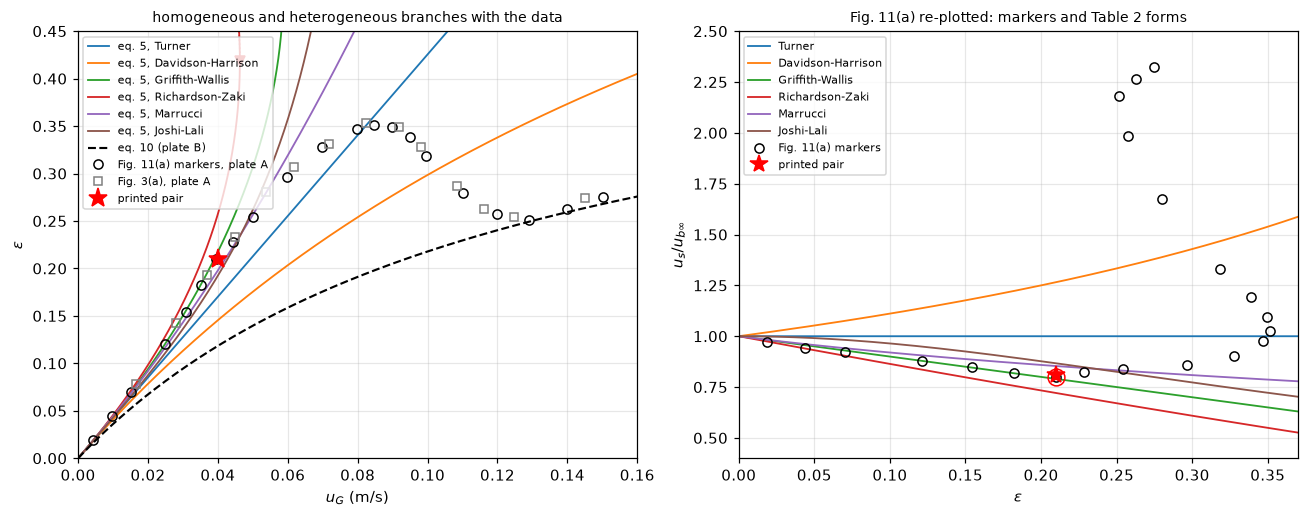

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ee = np.linspace(1e-4, 0.999, 4000)
for f, c in zip(FORMS, plt.cm.tab10.colors):
    uu = jh(f, ee, K, C)
    ok = (uu <= 0.16) & ((ee <= 0.5) | (f not in ("griffith_wallis", "richardson_zaki")))
    ax[0].plot(uu[ok], ee[ok], color=c, lw=1.2, label=f"eq. 5, {NAME[f]}")
    if f in ("griffith_wallis", "richardson_zaki"):
        em = M[f"r2_epsmax_{SHORT[f]}"]
        up = (ee > em) & (ee < 0.6)
        ax[0].plot(uu[up], ee[up], color=c, lw=1.0, ls=":")
        ax[0].plot(M[f"r2_uGmax_{SHORT[f]}"], em if em < 0.6 else np.nan, "v", color=c, ms=7)
    ax[1].plot(ee[ee < 0.37], phi(f, ee[ee < 0.37], K, C), color=c, lw=1.2, label=NAME[f])
uu = np.linspace(0, 0.16, 200)
ax[0].plot(uu, eps10(uu, K), "k--", lw=1.4, label="eq. 10 (plate B)")
ax[0].plot(u_, e_, "o", mfc="none", mec="k", ms=6, label="Fig. 11(a) markers, plate A")
a3 = C.f3[C.f3.plate == "A"]
ax[0].plot(a3.u_G, a3.eps_G, "s", mfc="none", mec="0.5", ms=5, label="Fig. 3(a), plate A")
ax[0].plot(K["u_G_crit"], K["eps_G_crit"], "r*", ms=13, label="printed pair")
ax[0].set(xlabel="$u_G$ (m/s)", ylabel=r"$\varepsilon$", xlim=(0, 0.16), ylim=(0, 0.45))
ax[0].legend(fontsize=7, loc="upper left")
ax[1].plot(e_, y_, "o", mfc="none", mec="k", ms=6, label="Fig. 11(a) markers")
ax[1].plot(M["r4_last_eps"], M["r4_last_uG"] / (M["r4_last_eps"] * C.ub_fig), "o", mfc="none", mec="r", ms=11)
ax[1].plot(K["eps_G_crit"], M["r1_slip_ratio_pair"], "r*", ms=12, label="printed pair")
ax[1].set(xlabel=r"$\varepsilon$", ylabel=r"$u_s/u_{b\infty}$", xlim=(0, 0.37), ylim=(0.4, 2.5))
ax[1].legend(fontsize=7, loc="upper left")
ax[0].set_title("homogeneous and heterogeneous branches with the data", fontsize=9)
ax[1].set_title("Fig. 11(a) re-plotted: markers and Table 2 forms", fontsize=9)
plt.tight_layout()
plt.show()

Left: eq. 5 for each form up to its flux maximum (triangles; dotted beyond), eq. 10,
and the plate A data; the red star is the printed pair. Right: the slip-velocity
ratio, the paper's own axes; the red ring marks the last marker on Griffith-Wallis.

### R5. The airlift riser

In [14]:
say("""Eq. 6 inserted in eq. 3 (cocurrent) is Zuber-Findlay exactly (E6): $u_G/\\varepsilon = j +
A_c u_{b\\infty}$, with $C_0$ = 1 and a drift velocity of <<ud:.5f>> m/s, so the paper's "has not been
hindered" (p. 3822) is a slip of 0.79 $u_{b\\infty}$ at zero holdup. At the printed slope breaks the
implied liquid velocity is <<l1:.3f>> and <<l2:.3f>> m/s; eq. 6 gives $\\varepsilon$ = <<e1:.4f>> and
<<e2:.4f>> ($u_s/u_{b\\infty}$ = <<s1:.4f>>, <<s2:.4f>>), the plate B line <<b1:.4f>> and <<b2:.4f>>.
The first break holds <<r1:.4f>> times the printed limit "eps_Gr > 0.15" of eq. 6. At the printed 0.067
and 0.235 m/s the verdict flips only for a riser $u_{b\\infty}$ above <<uf:.5f>> m/s; over the rounding of
those two inputs the flip spans <<ufl:.4f>> to <<ufh:.4f>> m/s, which contains the printed 0.263 and 0.267,
so the verdict is firm for 0.235 m/s only. The two riser lines meet at $j$ = <<cj:.5f>> m/s (<<nc>> crossings at
$j > 0$). Eq. 9 does not fix 1.07 by itself: with a velocity profile $1 - (r/R)^m$ the area average
gives $C_0$ = <<c7:.7f>> at $m$ = 7 (<<h7:.2f>> half-units from 1.07) and exactly 1.07 at $m$ =
<<m7:.4f>>.""",
    ud=M["r5_ud_eq6"], l1=M["r5_uL1"], l2=M["r5_uL2"], e1=M["r5_eps6_1"], e2=M["r5_eps6_2"], s1=M["r5_slip1"],
    s2=M["r5_slip2"], b1=M["r5_epsB_1"], b2=M["r5_epsB_2"], r1=M["r5_eps6_1_over_limit"], uf=M["r5_ub_flip"], ufl=M["r5_ub_flip_lo"], ufh=M["r5_ub_flip_hi"],
    cj=M["r5_cross_j"], nc=M["r5_n_cross_physical"], c7=M["r5_C0_m7"], h7=M["r5_hu_107"], m7=M["r5_m_for_107"])

Eq. 6 inserted in eq. 3 (cocurrent) is Zuber-Findlay exactly (E6): $u_G/\varepsilon = j +
A_c u_{b\infty}$, with $C_0$ = 1 and a drift velocity of 0.18565 m/s, so the paper's "has not been
hindered" (p. 3822) is a slip of 0.79 $u_{b\infty}$ at zero holdup. At the printed slope breaks the
implied liquid velocity is 0.168 and 0.180 m/s; eq. 6 gives $\varepsilon$ = 0.1593 and
0.2769 ($u_s/u_{b\infty}$ = 0.9397, 1.0925), the plate B line 0.1080 and 0.1868.
The first break holds 1.0618 times the printed limit "eps_Gr > 0.15" of eq. 6. At the printed 0.067
and 0.235 m/s the verdict flips only for a riser $u_{b\infty}$ above 0.26793 m/s; over the rounding of
those two inputs the flip spans 0.2631 to 0.2728 m/s, which contains the printed 0.263 and 0.267,
so the verdict is firm for 0.235 m/s only. The two riser lines meet at $j$ = -0.14875 m/s (0 crossings at
$j > 0$). Eq. 9 does not fix 1.07 by itself: with a velocity profile $1 - (r/R)^m$ the area average
gives $C_0$ = 1.0546875 at $m$ = 7 (3.06 half-units from 1.07) and exactly 1.07 at $m$ =
3.5000.

## Validation

**V1. Two routes for every root and extremum.** The check values (a second script)
are reproduced above to their tolerance; below, each root against a closed form or
the paper's fixed-point form of eq. 5, each maximum against $1/(1+n)$ and a bounded
maximisation refined from a scan of the window, the crossing against the
Griffith-Wallis quadratic, the wave speed against a central difference, E6 against
eq. 3 with eq. 6 solved by `find_roots`, the flip velocity against its closed form
and eq. 9's average against a quadrature.

In [15]:
V1 = {k: M[k] for k in M if k.startswith("v1_")}
for k, v in V1.items():
    print(f"{k:<22} {v:.1e}")
print(f"check values: {len(CHECK_DEV)} rows, worst relative {max(map(abs, CHECK_DEV.values())):.1e}")

v1_fixed_point_gap     2.2e-16
v1_closed_form_gap     2.8e-17
v1_max_closed_gap      0.0e+00
v1_max_bounded_gap     1.1e-09
v1_crossing_gap        1.7e-18
v1_wave_fd_gap         7.5e-14
v1_E6_gap              2.5e-16
v1_flip_closed_gap     5.6e-17
v1_eq9_quad_gap        4.4e-16
check values: 66 rows, worst relative 3.6e-12


**V2. The digitising.** The drawn Table 2 lines of Fig. 11(a) are read back against
their formulas, and the Fig. 11(a) markers, converted to $u_G$ with 0.235 m/s, are
compared with the plate A holdups of Fig. 3(a), the same column and plate at other
gas velocities. This tests the calibration, the drawing and the
$u_{b\infty}$ normalisation together.

In [16]:
say("""The <<nl>> line readings lie at most <<ld:.4f>> from their formulas: <<nlr>> of <<nl>> within the reading
error of a line, <<sl:.3f>> (the sidecar's 1 px, rounded up), and <<nlw>> of <<nl>> within 0.03, the stop rule set before the
reading. The departures beyond the reading error stay well inside the Griffith-Wallis to Marrucci gap
at $\\varepsilon$ = 0.210 (R1's table). The <<n3>> Fig. 3(a) markers on the rising branch differ from the
interpolated Fig. 11(a) holdups by at most <<d3:pct1>> (<<n3w>> of <<n3>> within 5 %, again the stop rule);
<<n3r>> of <<n3>> lie within three combined reading errors (the worst at <<zm:.2f>>). The two figures show the
same column, plate and conditions (Fig. 3(a) caption) at other gas velocities, so this tests the
normalisation by 0.235 m/s to that accuracy, not marker by marker.""",
    nl=M["v2_n_lines"], ld=M["v2_line_maxdev"], nlw=M["v2_n_lines_within"], nlr=M["v2_n_lines_read"], sl=SIG_LINE,
    n3=M["v2_f3_n"], d3=M["v2_f3_maxrel"], n3w=M["v2_f3_n_within"], n3r=M["v2_f3_n_read"], zm=M["v2_f3_max_z"])

The 38 line readings lie at most 0.0183 from their formulas: 16 of 38 within the reading
error of a line, 0.005 (the sidecar's 1 px, rounded up), and 38 of 38 within 0.03, the stop rule set before the
reading. The departures beyond the reading error stay well inside the Griffith-Wallis to Marrucci gap
at $\varepsilon$ = 0.210 (R1's table). The 8 Fig. 3(a) markers on the rising branch differ from the
interpolated Fig. 11(a) holdups by at most 3.7 % (8 of 8 within 5 %, again the stop rule);
7 of 8 lie within three combined reading errors (the worst at 3.40). The two figures show the
same column, plate and conditions (Fig. 3(a) caption) at other gas velocities, so this tests the
normalisation by 0.235 m/s to that accuracy, not marker by marker.

**V3. Eq. 10 against its own data.** A least-squares line through the markers of
Fig. 12(b) (plate B), $u_G/\varepsilon = C_0u_G + u_d$.

In [17]:
say("""The fit gives $C_0$ = <<c0:.3f>> ± <<cs:.3f>> and $u_d$ = <<ud:.4f>> ± <<us:.4f>> m/s (standard
errors), <<zc:+.2f>> and <<zu:+.2f>> standard errors from the printed 2.02 and 0.257 (<<n1>> of 2 inside
one). The holdups of Fig. 12(b) scatter about eq. 10 with an rms relative deviation of <<sd:pct2>>,
the yardstick of R4. The plate B holdups of Fig. 3(a) lie within <<f3:pct1>> of eq. 10.""",
    c0=M["v3_C0"], cs=M["v3_C0_se"], ud=M["v3_ud"], us=M["v3_ud_se"], zc=M["v3_z_C0"], zu=M["v3_z_ud"],
    n1=M["v3_n_inside_1se"], sd=M["v3_sd_rel"], f3=M["v3_f3B_maxrel"])

The fit gives $C_0$ = 2.043 ± 0.030 and $u_d$ = 0.2549 ± 0.0027 m/s (standard
errors), +0.78 and -0.77 standard errors from the printed 2.02 and 0.257 (2 of 2 inside
one). The holdups of Fig. 12(b) scatter about eq. 10 with an rms relative deviation of 0.89 %,
the yardstick of R4. The plate B holdups of Fig. 3(a) lie within 3.0 % of eq. 10.

### The finding

Neither fitted model fixes the transition. The homogeneous branch's own limit, the
flux maximum, lies well above the printed velocity for both forms that have one (R2),
and the four others have none; the two branches do not meet at the printed constants,
and with the two printed velocities that exceed the eq. 10 intercept (0.263 and 0.267 m/s) they meet only near zero holdup
(R3). The two fitted branches stay apart in holdup; the data pass from one to the other through a holdup maximum (R4). The printed pair is a
property of the data: it matches, within the reading error, the last Fig. 11(a) marker
on the Griffith-Wallis line (R4), consistent with that line once 0.04 is read as a rounded value (R1), and the
data rejoin eq. 10 from the printed 0.125 m/s. In the riser, eq. 6 and the
drift-flux breaks agree through an exact identity, and the first break sits above the
printed limit 0.15 (R5).

What this does not say: the pair holds for air-water, a 0.15 m column at $H_0/D_r$ =
10 and plate A only; Figs. 4 to 10 of the paper show it moving with distributor,
geometry and liquid. Whether a stability theory would predict it is not tested.

## What pymrm adds

Nothing beyond checks: there is no balance to discretise, and no pymrm operator is
used. `pymrm.checks.find_roots` finds every root of eq. 5 with its count, the flux
maxima as roots of the derivative, the branch crossings (an empty list is a result
here, confirmed by E13), the riser crossing, the flip velocity and the eq. 9
exponent, each over the whole physical range. The second routes are closed forms,
the fixed point, `scipy` bounded maximisation and quadrature (V1). What the page adds
to the paper is the test of the two model-intrinsic candidates for the transition
and the measured consistency of the printed numbers with each other and with three
of the paper's figures.

## Reuse

- Another hindrance function: add it to `phi` and `djh_numerator`; R1, R2 and the
  crossing scan follow. A form with a flux maximum returns two roots of eq. 5 below
  its maximum velocity.
- Another heterogeneous fit: change `C0_column_plateB` and `u_drift_column_plateB`;
  E13 says the branches can meet only where $u_{b\infty}\phi(1 - C_0\varepsilon)$ exceeds $u_d$.
- A riser with known $u_L$: E6 turns eq. 6 into Zuber-Findlay with $C_0$ = 1.
- Related pages: F1.3 (Wilkinson's transition correlation and holdup), F1.4
  (large-bubble holdup in the churn-turbulent regime), F1.1, F1.2 and F1.8 (holdup
  correlations).

In [18]:
# Every number of the page is a claim: a value, held to 1e-6 because the arithmetic is closed
# form and identical under the three BLAS kernels; an exact count, with its margin to the
# threshold that decides it; or a two-route gap with its bound.
RTOL = 1e-6
STRUCTURAL = {"v2_n_lines": "digitised line readings",
              "v3_n": "digitised marker count"}
BOUNDS = {"v1_fixed_point_gap": (1e-12, "tolerance", "find_roots xtol 1e-15 against a fixed point iterated to 1e-16"),
          "v1_closed_form_gap": (1e-12, "tolerance", "find_roots xtol 1e-15 against closed forms"),
          "v1_max_closed_gap": (1e-12, "tolerance", "root of the derivative numerator against 1/(1+n) and 1/2"),
          "v1_max_bounded_gap": (1e-7, "tolerance", "a flat maximum: the bounded search locates it to about the square root of machine epsilon"),
          "v1_crossing_gap": (1e-12, "tolerance", "E13 root against the Griffith-Wallis quadratic"),
          "v1_wave_fd_gap": (1e-9, "theory", "central difference of a quadratic is exact; round-off eps |j|/h is about 1e-12"),
          "v1_E6_gap": (1e-12, "identity", "E6 is eq. 3 with eq. 6 rearranged; the gap is the root tolerance"),
          "v1_flip_closed_gap": (1e-12, "tolerance", "find_roots against the closed form"),
          "v1_eq9_quad_gap": (1e-10, "tolerance", "closed-form average against quad at epsrel 1e-12")}
COUNTS = {"r1_n_forms_round_to_ucrit": 0.05, "r2_n_maxima_below_ucrit": 0.01, "r3_n_forms_crossing": 0.01,
          "r2_n_markers_above_ustar": 0.01, "r4_n_homog": 1.0, "r4_best": 0.05, "r4_second": 0.05,
          "r4_last_on": 0.05, "r4_first_off": 0.05, "r4_n_within_2sig": 0.05, "r4_n_full": 0.01,
          "r4_n_rejoin_within": 0.05, "v2_n_lines_within": 0.05, "v2_f3_n_within": 0.05, "v2_n_lines_read": 0.05, "v2_f3_n_read": 0.05, "v3_n_inside_1se": 0.05}
EXACT = {*(f"r1_nroots_{SHORT[f]}" for f in FORMS), "r2_n_maxima", "r3_n_forms_crossing_263",
         "r3_n_forms_crossing_267", "r3_n_eq14_interior_maxima", "r5_n_cross_physical", "v2_f3_n", "r4_n_markers", "r3_n_forms_slip_above_one"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            mx, basis, note = BOUNDS[name]
            claims.bound(name, v, max=mx, basis=basis, note=note,
                         structural=name not in {"v1_closed_form_gap", "v1_max_closed_gap", "v1_crossing_gap"})
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=RTOL)


register(M)

### The break table

Every non-structural number registered above has a row that moves it. Each row
mistypes one printed constant by 10 % (by 1 % where 10 % leaves no solution), or makes one named substitution (a form for
another, a constant from elsewhere in the paper, a misread equation), or changes one
set of figure readings, and reruns the whole study; the claims it fails are counted.
A row records only finite values: a claim that a row removes (a root that no longer
exists) is not counted as caught by that row. The controls fail nothing.

In [19]:
UNUSED = {"u_G_onset_fig3a", "C0_riser_plateA_section1", "eq14_Hd_lower_limit"}


def mistyped(name, f=1.1):
    v = K[name] * f
    return f"{name} {PRINTED[name]} -> {v:.6g}", {**K, name: v}, C


def set_to(label, name, v):
    return f"{label}: {name} {PRINTED[name]} -> {v:g}", {**K, name: v}, C


def form_as(form, other):
    return f"Table 2 {NAME[form]} replaced by {NAME[other]}", K, replace(C, forms={**C.forms, form: other})


def fig11(col, f, every=1, kind="marker"):
    df = C.f11.copy()
    m = (df.kind == kind) & (np.arange(len(df)) % every == 0)
    df.loc[m, col] = df.loc[m, col] * f
    what = "every" if every == 1 else f"every {every}th"
    return f"Fig. 11(a) {kind} {col} x {f:g}, {what}", K, replace(C, f11=df)


def scaled(fig, col, f, plate=None):
    df = getattr(C, fig).copy()
    m = np.ones(len(df), bool) if plate is None else (df.plate == plate).to_numpy()
    df.loc[m, col] = df.loc[m, col] * f
    return f"{fig} {col} x {f:g}" + (f", plate {plate}" if plate else ""), K, replace(C, **{fig: df})


def drop_marker(i):
    df = C.f11[~((C.f11.kind == "marker") & (C.f11.series == i))].reset_index(drop=True)
    return f"Fig. 11(a) marker {i} dropped", K, replace(C, f11=df)


DEFECTS = [mistyped(k, 1.01 if k == "C0_zuber_findlay_theory" else 1.1) for k in K if k not in UNUSED] + [
    form_as("griffith_wallis", "richardson_zaki"), form_as("griffith_wallis", "turner"),
    form_as("davidson_harrison", "griffith_wallis"), form_as("turner", "griffith_wallis"),
    form_as("marrucci", "richardson_zaki"),
    set_to("Joshi-Lali exponent read as 1.2", "joshi_lali_exponent_fig11b", 1.2),
    set_to("eq. 10 with C0 below one", "C0_column_plateB", 0.9),
    set_to("eq. 5 with the eq. 10 intercept", "u_b_inf_homogeneous", K["u_drift_column_plateB"]),
    set_to("eq. 5 with the eq. 14 velocity", "u_b_inf_homogeneous", K["u_b_inf_clift"]),
    set_to("Richardson-Zaki exponent", "rz_exponent_air_water", 4.65),
    set_to("eq. 10", "C0_column_plateB", 2.0),
    set_to("eq. 12 with the eq. 10 intercept", "mashelkar_velocity", K["u_drift_column_plateB"]),
    set_to("eq. 14 offset sign", "eq14_J_offset", -K["eq14_J_offset"]),
    set_to("riser", "A_c", 1.0), set_to("riser", "A_c", 1.2),
    set_to("eq. 9 void exponent", "eq9_void_exponent", 2.0),
    ("eq. 13 with rho_L for rho_L^2", K, replace(C, rho_pow=1.0)),
    ("eq. 14 groups as printed (M1, M2)", K, replace(C, printed_groups=True)),
    ("eq. 14 with mu_w 0.001", K, replace(C, mu_w=1.0e-3)),
    ("water at 25 C for 20 C", K, replace(C, water={**C.water, 20: WATER[25]})),
    ("Fig. 11(a) normalised with 0.257", K, replace(C, ub_fig=K["u_drift_column_plateB"])),
    ("Marrucci as the reference of the departure", K, replace(C, ref="marrucci")),
    ("riser constants in eq. 10 for R4", K, replace(C, het=("C0_riser_plateB", "u_drift_riser_plateB"))),
    ("reading error sigma_y doubled", K, replace(C, sig_y=2 * SIG_Y)),
    ("reading error sigma_eps x 5", K, replace(C, sig_eps=5 * SIG_EPS)),
    fig11("eps_G", 1.03), fig11("us_over_ubinf", 1.03), fig11("us_over_ubinf", 0.97),
    fig11("us_over_ubinf", 1.05, every=2), fig11("us_over_ubinf", 1.05, every=2, kind="line"),
    drop_marker(7), drop_marker(21),
    scaled("f3", "eps_G", 1.05, "A"), scaled("f3", "eps_G", 1.05, "B"),
    scaled("f12", "uG_over_eps", 1.05), scaled("f12", "u_G", 1.1),
]
CONTROLS = [("control: clean rerun", K, C),
            ("control: Fig. 11(a) rows in reverse order", K, replace(C, f11=C.f11.iloc[::-1].reset_index(drop=True)))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK = []
FAILED.clear()
for row, k_, c_ in CONTROLS + DEFECTS:
    n0 = len(FAILED)
    Mb = study(k_, c_, tolerant=True)
    FAILED[n0:] = [f"{row}: {x}" for x in FAILED[n0:]]
    for name in claims.metrics:
        v = Mb.get(name)
        if v is not None and np.isfinite(float(v)):   # only finite values are recorded
            BREAK.append((row, name, claims.breaks(row, name, v)))

In [20]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<62} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:62]:<62} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
print("parts of the study that cannot run under a row (their claims record nothing for it):")
print("\n".join(f"  {x}" for x in FAILED) or "  none")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {sum(bool(c.get('structural')) for c in claims.metrics.values())}; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                                claims failed
control: clean rerun                                                       0
control: Fig. 11(a) rows in reverse order                                  0
u_b_inf_homogeneous 0.235 -> 0.2585                                       61
u_G_crit 0.04 -> 0.044                                                    23
eps_G_crit 0.210 -> 0.231                                                 35
u_G_heterogeneous_full 0.125 -> 0.1375                                     7
rz_exponent_air_water 1.39 -> 1.529                                       15
marrucci_exponent 5/3 -> 1.83333                                          10
joshi_lali_coefficient 7.5 -> 8.25                                         5
joshi_lali_exponent_fig11b 1/2 -> 0.55                                     5
A_c 0.79 -> 0.869                                                         10
eps_Gr_limit_riser 0.15 -> 0.165                                           4

In [21]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F1.9:
  r1_nroots_turner          = 1                exact  exact
  r1_eps_turner             = 0.17021          value  rtol 1e-06
  r1_uG_turner              = 0.04935          value  rtol 1e-06
  r1_hu_u_turner            = 1.87             value  rtol 1e-06
  r1_nroots_dh              = 1                exact  exact
  r1_eps_dh                 = 0.14545          value  rtol 1e-06
  r1_uG_dh                  = 0.062468         value  rtol 1e-06
  r1_hu_u_dh                = 4.4937           value  rtol 1e-06
  r1_phi_dh                 = 1.2658           value  rtol 1e-06
  r1_nroots_gw              = 2                exact  exact
  r1_eps_gw                 = 0.21753          value  rtol 1e-06
  r1_eps_upper_gw           = 0.78247          value  rtol 1e-06
  r1_uG_gw                  = 0.038987         value  rtol 1e-06
  r1_hu_u_gw                = 0.2027           value  rtol 1e-06
  r1_phi_gw                 = 0.79             value  rtol 1e-06
  r1_nroots_rz         